## 1. Setup

In [3]:
import os, sys, json, time, math, warnings, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import yfinance as yf
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import wilcoxon
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 300)

np.random.seed(42)

# Folder data mentah (cache unduhan) dan folder hasil run final.
# Nama folder hasil dipertahankan "workspace_audit" supaya checkpoint run yang sudah selesai terbaca ulang
# (run_one() memakai checkpoint yang ada, jadi run penuh tidak diulang dari nol).
WORK = Path("workspace")
OUT = Path("workspace_audit")
for d in [WORK / "raw", OUT / "opt", OUT / "final", OUT / "final" / "plots_prediksi"]:
    d.mkdir(parents=True, exist_ok=True)

N_JOBS = max(1, (os.cpu_count() or 2) - 1)
print("Setup OK | N_JOBS =", N_JOBS, "| folder hasil:", OUT.resolve())

Setup OK | N_JOBS = 11 | folder hasil: D:\tugas akhir\code lq45\workspace_audit


## 2. Pengumpulan Data

In [ ]:
# Universe kandidat: 45 anggota LQ45 per Pengumuman BEI No. Peng-00198/BEI.POP/10-2025 (efektif 3 Nov 2025 - 30 Jan 2026).
LQ45_45 = [
    "AADI","ACES","ADMR","ADRO","AKRA","AMMN","AMRT","ANTM","ASII","BBCA",
    "BBNI","BBRI","BBTN","BMRI","BRPT","BUMI","CPIN","CTRA","DSSA","EMTK",
    "EXCL","GOTO","HEAL","ICBP","INCO","INDF","INKP","ISAT","ITMG","JPFA",
    "KLBF","MAPI","MBMA","MDKA","MEDC","NCKL","PGAS","PGEO","PTBA","SCMA",
    "SMGR","TLKM","TOWR","UNTR","UNVR",
]
assert len(LQ45_45) == 45
UNIVERSE_RAW = sorted(LQ45_45)   # tidak ada exclude manual; saham yang masuk universe final ditentukan otomatis di Bagian 4

START, END = "2021-01-01", "2026-01-01"   # END eksklusif -> Des 2025 ikut terunduh
OHLCV = ["Open", "High", "Low", "Close", "Volume"]

# auto_adjust=False: Close = harga mentah (Adj Close memuat informasi masa depan).
def download_ticker(code):
    path = WORK / "raw" / f"{code}.csv"
    if path.exists():
        return pd.read_csv(path, index_col=0, parse_dates=True)
    df = yf.download(f"{code}.JK", start=START, end=END, auto_adjust=False, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[OHLCV].dropna(how="all")
    df.to_csv(path)
    return df

prices_raw = {}
for i, c in enumerate(UNIVERSE_RAW, 1):
    try:
        prices_raw[c] = download_ticker(c)
        print(f"[{i:2d}/45] {c:6s} OK  | {len(prices_raw[c])} baris | "
              f"{prices_raw[c].index.min().date()} s/d {prices_raw[c].index.max().date()}")
    except Exception as e:
        print(f"[{i:2d}/45] {c:6s} GAGAL: {e}")
print(f"\nTotal berhasil diunduh: {len(prices_raw)}/45")

[ 1/45] AADI   OK  | 252 baris | 2024-12-05 s/d 2025-12-30
[ 2/45] ACES   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[ 3/45] ADMR   OK  | 958 baris | 2022-01-03 s/d 2025-12-30
[ 4/45] ADRO   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[ 5/45] AKRA   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[ 6/45] AMMN   OK  | 594 baris | 2023-07-07 s/d 2025-12-30
[ 7/45] AMRT   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[ 8/45] ANTM   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[ 9/45] ASII   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[10/45] BBCA   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[11/45] BBNI   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[12/45] BBRI   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[13/45] BBTN   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[14/45] BMRI   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[15/45] BRPT   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[16/45] BUMI   OK  | 1205 baris | 2021-01-04 s/d 2025-12-30
[17/45] CPIN   OK  | 1205 baris | 2021-01-0

## 3. Data Understanding (EDA)

### 3.1 Statistik deskriptif

In [ ]:
rows = []
for c, df in prices_raw.items():
    cl = df["Close"]
    rows.append(dict(ticker=c, n_hari=len(df), tgl_awal=df.index.min().date(), tgl_akhir=df.index.max().date(),
                      mean=cl.mean(), std=cl.std(), min=cl.min(), q1=cl.quantile(.25),
                      median=cl.median(), q3=cl.quantile(.75), max=cl.max(), skew=cl.skew()))
desc = pd.DataFrame(rows).set_index("ticker").sort_index()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
display(desc)

baru = desc[desc["tgl_awal"] > pd.Timestamp("2021-01-04").date()]
print(f"\n{len(baru)} saham memiliki tgl_awal setelah 2021-01-04 (tidak memenuhi syarat inklusi riwayat penuh):")
display(baru[["tgl_awal", "n_hari"]])

,n_hari,tgl_awal,tgl_akhir,mean,std,min,q1,median,q3,max,skew
ticker,,,,,,,,,,,
AADI,252,2024-12-05,2025-12-30,"7,455.46",775.55,"5,750.00","6,950.00","7,200.00","7,856.25","10,275.00",0.88
ACES,1205,2021-01-04,2025-12-30,862.52,358.96,398.00,550.00,775.00,"1,070.00","1,800.00",0.74
ADMR,958,2022-01-03,2025-12-30,"1,347.22",379.46,135.00,"1,070.00","1,320.00","1,513.75","2,990.00",0.98
ADRO,1205,2021-01-04,2025-12-30,"2,449.92",792.22,"1,160.00","1,815.00","2,440.00","2,950.00","4,140.00",0.17
AKRA,1205,2021-01-04,2025-12-30,"1,195.30",316.97,562.00,900.00,"1,255.00","1,440.00","1,850.00",-0.38
AMMN,594,2023-07-07,2025-12-30,"7,824.45","2,134.89","1,750.00","6,650.00","7,725.00","9,025.00","13,200.00",-0.29
AMRT,1205,2021-01-04,2025-12-30,"2,196.19",731.31,765.00,"1,420.00","2,390.00","2,840.00","3,570.00",-0.49
ANTM,1205,2021-01-04,2025-12-30,"2,119.15",542.21,"1,210.00","1,655.00","2,010.00","2,420.00","3,670.00",0.58
ASII,1205,2021-01-04,2025-12-30,"5,681.12",738.88,"4,290.00","5,075.00","5,650.00","6,300.00","7,575.00",0.22



7 saham memiliki tgl_awal setelah 2021-01-04 (tidak memenuhi syarat inklusi riwayat penuh):


,tgl_awal,n_hari
ticker,,
AADI,2024-12-05,252
ADMR,2022-01-03,958
AMMN,2023-07-07,594
GOTO,2022-04-11,891
MBMA,2023-04-18,640
NCKL,2023-04-12,644
PGEO,2023-02-24,674


### 3.2 Uji stasioneritas (ADF): level harga vs log-return

In [ ]:
def adf_summary(series):
    series = series.dropna()
    try:
        stat, p, *_ = adfuller(series, autolag="AIC")
        return stat, p
    except Exception:
        return np.nan, np.nan

rows = []
for c, df in prices_raw.items():
    cl = df["Close"]
    logret = np.log(cl / cl.shift(1)).dropna()
    s_lvl, p_lvl = adf_summary(cl)
    s_ret, p_ret = adf_summary(logret)
    rows.append(dict(ticker=c, adf_stat_level=s_lvl, p_level=p_lvl, stasioner_level_5pct=p_lvl < 0.05,
                      adf_stat_return=s_ret, p_return=p_ret, stasioner_return_5pct=p_ret < 0.05))
adf_tbl = pd.DataFrame(rows).set_index("ticker").sort_index()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
display(adf_tbl)
print(f"\n{int((~adf_tbl['stasioner_level_5pct']).sum())}/{len(adf_tbl)} saham: harga LEVEL tidak stasioner (p>=0.05).")
print(f"{int(adf_tbl['stasioner_return_5pct'].sum())}/{len(adf_tbl)} saham: LOG-RETURN stasioner (p<0.05).")

,adf_stat_level,p_level,stasioner_level_5pct,adf_stat_return,p_return,stasioner_return_5pct
ticker,,,,,,
AADI,-2.9446,0.0404,True,-15.2144,0.0000,True
ACES,-2.3080,0.1694,False,-35.2893,0.0000,True
ADMR,-2.6572,0.0817,False,-26.2817,0.0000,True
ADRO,-1.8437,0.3590,False,-33.8217,0.0000,True
AKRA,-1.8831,0.3401,False,-18.9899,0.0000,True
AMMN,-2.8060,0.0574,False,-25.0768,0.0000,True
AMRT,-1.9297,0.3182,False,-37.7356,0.0000,True
ANTM,-1.7416,0.4098,False,-34.0467,0.0000,True
ASII,-1.9267,0.3196,False,-39.2911,0.0000,True



42/45 saham: harga LEVEL tidak stasioner (p>=0.05).
45/45 saham: LOG-RETURN stasioner (p<0.05).


### 3.3 Autokorelasi (ACF) log-return

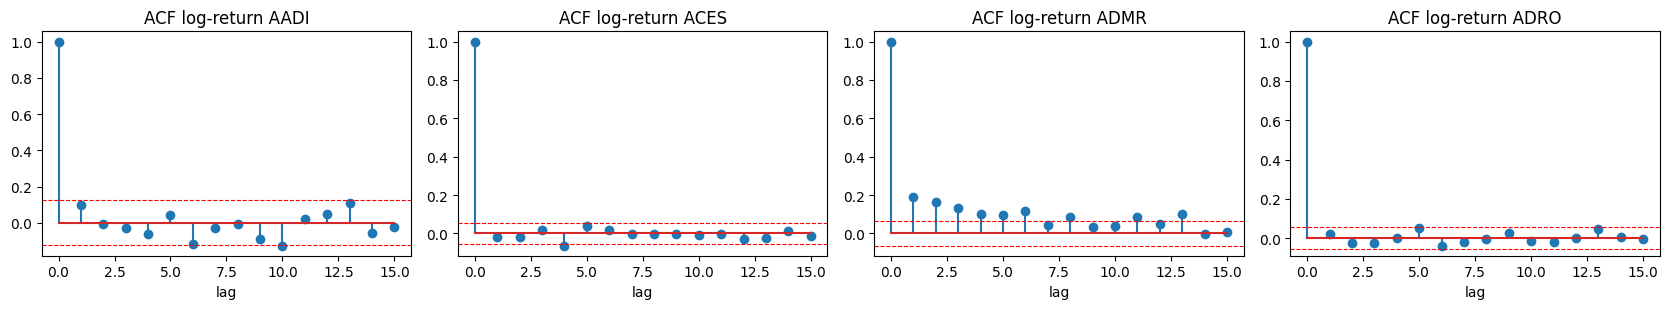

,n_lag_signifikan
ticker,
ADMR,9
BBRI,3
EXCL,3
BRPT,3
BMRI,3
MEDC,3
INCO,2
CTRA,2
DSSA,2


In [ ]:
sample_tickers = list(prices_raw.keys())[:4]
fig, axes = plt.subplots(1, len(sample_tickers), figsize=(4.2 * len(sample_tickers), 3.2))
for ax, c in zip(np.atleast_1d(axes), sample_tickers):
    logret = np.log(prices_raw[c]["Close"] / prices_raw[c]["Close"].shift(1)).dropna()
    acf_vals = acf(logret, nlags=15, fft=True)
    ax.stem(range(len(acf_vals)), acf_vals)
    ax.axhline(1.96 / np.sqrt(len(logret)), color="red", ls="--", lw=0.8)
    ax.axhline(-1.96 / np.sqrt(len(logret)), color="red", ls="--", lw=0.8)
    ax.set_title(f"ACF log-return {c}"); ax.set_xlabel("lag")
plt.tight_layout(); plt.show()

acf_rows = []
for c, df in prices_raw.items():
    logret = np.log(df["Close"] / df["Close"].shift(1)).dropna()
    acf_vals = acf(logret, nlags=15, fft=True)
    acf_rows.append(dict(ticker=c, n_lag_signifikan=int(np.sum(np.abs(acf_vals[1:]) > 1.96 / np.sqrt(len(logret))))))
df_acf_summary = pd.DataFrame(acf_rows).set_index("ticker").sort_values("n_lag_signifikan", ascending=False)
display(df_acf_summary)

### 3.4 Volatilitas harian (std log-return) dan return ekstrem

In [ ]:
vol_rows, extreme_rows = [], []
for c, df in prices_raw.items():
    logret = np.log(df["Close"] / df["Close"].shift(1)).dropna()
    vol_rows.append(dict(ticker=c, std_logret_harian=logret.std(ddof=1)))
    n_ext = int((logret.abs() > 0.20).sum())
    if n_ext > 0:
        extreme_rows.append(dict(ticker=c, n_hari_return_ekstrem_20pct=n_ext, max_abs_return=float(logret.abs().max())))
vol_tbl = pd.DataFrame(vol_rows).set_index("ticker").sort_values("std_logret_harian")
pd.set_option("display.float_format", lambda v: f"{v:,.5f}")
display(vol_tbl)
print("\nSaham dengan hari return harian >20% (indikasi aksi korporasi/anomali):")
display(pd.DataFrame(extreme_rows).set_index("ticker")) if extreme_rows else print("Tidak ada.")

,std_logret_harian
ticker,
BBCA,0.01465
INDF,0.01488
ICBP,0.01642
ASII,0.01789
TLKM,0.01817
BBRI,0.01834
BMRI,0.01889
BBNI,0.01915
HEAL,0.02002



Saham dengan hari return harian >20% (indikasi aksi korporasi/anomali):


,n_hari_return_ekstrem_20pct,max_abs_return
ticker,,
ADMR,9,0.29873
ADRO,2,0.28496
AKRA,1,0.20067
BRPT,3,0.22124
BUMI,4,0.29092
EMTK,1,0.22075
GOTO,3,0.29908
MBMA,2,0.22314


### 3.5 Kualitas data: missing value, duplikat, likuiditas

In [ ]:
rows = []
for c, df in prices_raw.items():
    rows.append(dict(ticker=c, n_missing_total=int(df[OHLCV].isna().sum().sum()),
                      n_tanggal_duplikat=int(df.index.duplicated().sum()),
                      n_baris_duplikat_persis=int(df.duplicated().sum()),
                      tanggal_terurut=bool(df.index.is_monotonic_increasing)))
cleaning_report = pd.DataFrame(rows).set_index("ticker").sort_index()
bermasalah = cleaning_report[(cleaning_report["n_missing_total"] > 0) | (cleaning_report["n_tanggal_duplikat"] > 0) |
                              (cleaning_report["n_baris_duplikat_persis"] > 0) | (~cleaning_report["tanggal_terurut"])]
print(f"{len(bermasalah)} dari {len(cleaning_report)} saham terflag (missing / tanggal duplikat / baris duplikat persis / tidak terurut):")
display(bermasalah)

# Detail rentetan hari duplikat (harga beku) pada saham yang terflag
rows = []
for c in bermasalah.index:
    df = prices_raw[c]
    dup_mask = df.duplicated(keep=False)
    dup_dates = df.index[dup_mask]
    streaks = []
    if len(dup_dates) > 0:
        run_len, prev = 1, dup_dates[0]
        for d in dup_dates[1:]:
            if (d - prev).days <= 4:
                run_len += 1
            else:
                streaks.append(run_len); run_len = 1
            prev = d
        streaks.append(run_len)
    vol_on_dup = df.loc[dup_mask, "Volume"]
    rows.append(dict(ticker=c, n_hari_duplikat=int(dup_mask.sum()), pct_hari_duplikat=round(100 * dup_mask.sum() / len(df), 2),
                      rentetan_terpanjang=max(streaks) if streaks else 0, n_rentetan=len(streaks),
                      pct_volume_nol_saat_duplikat=round(100 * (vol_on_dup == 0).mean(), 1) if len(vol_on_dup) else 0.0))
if rows:
    display(pd.DataFrame(rows).set_index("ticker").sort_values("pct_hari_duplikat", ascending=False))

# Likuiditas: persentase hari dengan Volume = 0
liq_tbl = pd.DataFrame([dict(ticker=c, n_hari=len(df), n_hari_volume_nol=int((df["Volume"] == 0).sum()),
                              pct_hari_volume_nol=round(100 * (df["Volume"] == 0).mean(), 2))
                         for c, df in prices_raw.items()]).set_index("ticker").sort_values("pct_hari_volume_nol", ascending=False)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
display(liq_tbl.head(15))
print(f"\nMedian pct_hari_volume_nol seluruh 45 kandidat: {liq_tbl['pct_hari_volume_nol'].median():.2f}%")

8 dari 45 saham terflag (missing / tanggal duplikat / baris duplikat persis / tidak terurut):


,n_missing_total,n_tanggal_duplikat,n_baris_duplikat_persis,tanggal_terurut
ticker,,,,
ADMR,0,0,3,True
AMMN,0,0,1,True
DSSA,0,0,343,True
GOTO,0,0,1,True
ISAT,0,0,2,True
MBMA,0,0,1,True
NCKL,0,0,1,True
PGEO,0,0,1,True


,n_hari_duplikat,pct_hari_duplikat,rentetan_terpanjang,n_rentetan,pct_volume_nol_saat_duplikat
ticker,,,,,
DSSA,432,35.85000,59,54,83.30000
ADMR,5,0.52000,3,2,100.00000
AMMN,2,0.34000,2,1,100.00000
MBMA,2,0.31000,2,1,100.00000
NCKL,2,0.31000,2,1,100.00000
PGEO,2,0.30000,2,1,100.00000
ISAT,3,0.25000,3,1,100.00000
GOTO,2,0.22000,2,1,100.00000


,n_hari,n_hari_volume_nol,pct_hari_volume_nol
ticker,,,
DSSA,1205,384,31.87
ADMR,958,8,0.84
AMMN,594,3,0.51
MBMA,640,3,0.47
NCKL,644,3,0.47
PGEO,674,3,0.45
GOTO,891,3,0.34
ISAT,1205,3,0.25
ITMG,1205,1,0.08



Median pct_hari_volume_nol seluruh 45 kandidat: 0.00%


Temuan: DSSA memiliki sekitar 36% hari duplikat (rentetan terpanjang 59 hari, mayoritas Volume = 0), yaitu pola harga beku tanpa transaksi. Pada saham lain, hari duplikat hanya 2–5 hari (<1%) dan tidak material. Kriteria likuiditas pada Bagian 4 (maks. 5% hari Volume = 0) menyaring saham seperti DSSA secara otomatis.

## 4. Validasi universe (inklusi otomatis)

In [ ]:
def validate_universe(prices, max_pct_vol_zero=5.0):
    # Kalender acuan hanya dari saham dengan riwayat penuh sejak 2021-01-04 (saham IPO baru tidak menarik turun kalender acuan).
    full_hist = {c: df for c, df in prices.items() if df.index.min() <= pd.Timestamp("2021-01-04")}
    common_calendar = set.intersection(*[set(df.index) for df in full_hist.values()]) if full_hist else set()
    rows = []
    for c, df in prices.items():
        first_ok = df.index.min() <= pd.Timestamp("2021-01-04")
        cal_ok = first_ok and (set(df.index) == common_calendar)
        has_zero_or_neg = bool((df[["Open", "High", "Low", "Close"]] <= 0).any().any())
        pct_vol0 = 100 * (df["Volume"] == 0).mean()
        likuid_ok = pct_vol0 <= max_pct_vol_zero
        rows.append(dict(ticker=c, n_hari=len(df), tgl_pertama=df.index.min().date(), first_date_ok=first_ok,
                          kalender_identik=cal_ok, ada_harga_nonpositif=has_zero_or_neg,
                          pct_hari_volume_nol=round(pct_vol0, 2), likuiditas_ok=likuid_ok,
                          LOLOS=first_ok and cal_ok and not has_zero_or_neg and likuid_ok))
    return pd.DataFrame(rows).set_index("ticker").sort_index(), common_calendar

def _alasan_exclude(row):
    alasan = []
    if not row["first_date_ok"]:
        alasan.append("riwayat data tidak sampai 4 Jan 2021 (IPO/listing terlalu baru)")
    elif not row["kalender_identik"]:
        alasan.append("kalender perdagangan tidak sama dengan saham full-history lain")
    if row["ada_harga_nonpositif"]:
        alasan.append("ada harga <= 0")
    if not row["likuiditas_ok"]:
        alasan.append(f"likuiditas tidak memadai ({row['pct_hari_volume_nol']}% hari volume=0, ambang 5%)")
    return "; ".join(alasan) if alasan else "-"

validation_report, common_calendar = validate_universe(prices_raw)
UNIVERSE = sorted([c for c in validation_report.index if validation_report.loc[c, "LOLOS"]])
print(f"{len(UNIVERSE)}/{len(prices_raw)} saham lolos validasi.\n")

gagal_idx = [c for c in prices_raw if c not in UNIVERSE]
gagal_tbl = validation_report.loc[gagal_idx].copy()
gagal_tbl["alasan"] = gagal_tbl.apply(_alasan_exclude, axis=1)
print(f"{len(gagal_idx)} saham dikeluarkan otomatis:")
display(gagal_tbl[["alasan"]])

prices = {c: prices_raw[c].loc[sorted(common_calendar)].ffill() for c in UNIVERSE}

37/45 saham lolos validasi.

8 saham dikeluarkan otomatis:


,alasan
ticker,
AADI,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
ADMR,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
AMMN,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
DSSA,likuiditas tidak memadai (31.87% hari volume=0...
GOTO,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
MBMA,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
NCKL,riwayat data tidak sampai 4 Jan 2021 (IPO/list...
PGEO,riwayat data tidak sampai 4 Jan 2021 (IPO/list...


## 5. Data Preparation

### 5.1 Fitur, target, dan uji anti-leakage
Fitur: OHLCV hari *t*, lag 1…L untuk OHLCV, serta fitur kalender. Target: Close(*t*+1). Kolom `target_date` (tanggal hari bursa *t*+1) dipakai untuk menentukan baris masuk ke train/val/test, sehingga label setiap bagian tidak melewati batas periodenya.

In [ ]:
def make_features(df, L):
    X = df[OHLCV].copy()
    for k in range(1, L + 1):
        for col in OHLCV:
            X[f"{col}_lag{k}"] = df[col].shift(k)
    X["day_of_week"] = df.index.dayofweek
    X["day_of_month"] = df.index.day
    X["month"] = df.index.month
    X["year"] = df.index.year
    y = df["Close"].shift(-1)                                       # target: Close(t+1)
    tdate = pd.Series(df.index, index=df.index).shift(-1)           # tanggal target = hari bursa berikutnya
    out = pd.concat([X, y.rename("y"), tdate.rename("target_date")], axis=1).dropna()
    out["target_date"] = pd.to_datetime(out["target_date"])
    return out

def feature_cols(L):
    cols = list(OHLCV)
    for k in range(1, L + 1):
        for col in OHLCV:
            cols.append(f"{col}_lag{k}")
    return cols + ["day_of_week", "day_of_month", "month", "year"]

def run_leakage_tests(df, L=2, n_sample=15, seed=0):
    rng = np.random.default_rng(seed)
    full = make_features(df, L)
    cols = feature_cols(L)
    ok_trunc, checked = True, 0
    candidate_idx = list(range(L + 5, len(df) - 1))
    for t in rng.choice(candidate_idx, size=min(n_sample, len(candidate_idx)), replace=False):
        trunc = make_features(df.iloc[:t + 1], L)
        if len(trunc) == 0 or trunc.index[-1] not in full.index:
            continue
        if not np.allclose(trunc.iloc[-1][cols].values.astype(float), full.loc[trunc.index[-1], cols].values.astype(float)):
            ok_trunc = False
        checked += 1
    ok_target = bool((full["y"] == df["Close"].shift(-1).loc[full.index]).all())
    nxt = pd.Series(df.index, index=df.index).shift(-1).loc[full.index]
    ok_tdate = bool((full["target_date"] == nxt).all())
    return ok_trunc, checked, ok_target, ok_tdate

contoh = UNIVERSE[0]
ok_trunc, n_checked, ok_target, ok_tdate = run_leakage_tests(prices[contoh], L=2)
print(f"Uji truncation ({contoh}, {n_checked} baris): {'LULUS' if ok_trunc else 'GAGAL'}")
print(f"Uji target (y == Close.shift(-1))           : {'LULUS' if ok_target else 'GAGAL'}")
print(f"Uji target_date (= hari bursa berikutnya)   : {'LULUS' if ok_tdate else 'GAGAL'}")
assert ok_trunc and ok_target and ok_tdate

Uji truncation (ACES, 15 baris): LULUS
Uji target (y == Close.shift(-1))           : LULUS
Uji target_date (= hari bursa berikutnya)   : LULUS


### 5.2 Metrik evaluasi
MAPE, RMSE, MAE, dan R² dihitung pada skala Rupiah (setelah inverse transform).

In [ ]:
def mape(y_true, y_pred): return float(100 * np.mean(np.abs((y_true - y_pred) / y_true)))
def rmse(y_true, y_pred): return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
def mae(y_true, y_pred):  return float(np.mean(np.abs(y_true - y_pred)))
def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return float(1 - ss_res / ss_tot)

def all_metrics(y_true, y_pred):
    return dict(MAPE=mape(y_true, y_pred), RMSE=rmse(y_true, y_pred), MAE=mae(y_true, y_pred), R2=r2(y_true, y_pred))

### 5.3 Batas split (tanggal), pemilihan jumlah lag, split + scaling
Batas split dinyatakan dalam **tanggal** (70% / 85% dari kalender bersama seluruh saham). Jumlah lag dipilih dari validation MAPE pada 7 saham pilot (sebaran kuantil volatilitas, dihitung dari data train saja) dengan aturan 1-SE; test set tidak dipakai di langkah ini.

In [ ]:
raw_common = sorted(set.intersection(*[set(prices[c].index) for c in UNIVERSE]))
n_raw = len(raw_common)
CUT_TRAIN = raw_common[int(n_raw * 0.70) - 1]
CUT_VAL = raw_common[int(n_raw * 0.85) - 1]
print(f"CUT_TRAIN = {CUT_TRAIN.date()} | CUT_VAL = {CUT_VAL.date()}")

def split_by_target_date(feat):
    td = feat["target_date"]
    return feat[td <= CUT_TRAIN], feat[(td > CUT_TRAIN) & (td <= CUT_VAL)], feat[td > CUT_VAL]

# Volatilitas dari data train saja (tidak memakai informasi val/test)
vol_train = pd.Series({c: np.log(prices[c]["Close"] / prices[c]["Close"].shift(1)).loc[lambda s: s.index <= CUT_TRAIN].std()
                       for c in UNIVERSE}).sort_values()

N_PILOT_LAG = 7
idx_q = np.linspace(0, len(vol_train) - 1, N_PILOT_LAG).round().astype(int)
PILOTS_LAG = sorted(set(vol_train.index[idx_q]))
print(f"Saham pilot pemilihan lag ({len(PILOTS_LAG)}): {PILOTS_LAG}")

rows = []
for L in [1, 2, 3, 5, 10]:
    cols = feature_cols(L)
    for c in PILOTS_LAG:
        tr, va, _ = split_by_target_date(make_features(prices[c], L))
        m = xgb.XGBRegressor(objective="reg:squarederror", tree_method="hist", min_child_weight=1, random_state=42, n_jobs=1)
        m.fit(tr[cols], tr["y"])
        rows.append(dict(L=L, ticker=c, val_MAPE=mape(va["y"].values, m.predict(va[cols]))))
lag_pivot = pd.DataFrame(rows).pivot_table(index="L", columns="ticker", values="val_MAPE")
lag_pivot["rata_rata"] = lag_pivot[PILOTS_LAG].mean(axis=1)
lag_pivot["sd"] = lag_pivot[PILOTS_LAG].std(axis=1, ddof=1)
lag_pivot["se"] = lag_pivot["sd"] / np.sqrt(len(PILOTS_LAG))
display(lag_pivot.round(4))

L_terbaik = lag_pivot["rata_rata"].idxmin()
ambang = lag_pivot.loc[L_terbaik, "rata_rata"] + lag_pivot.loc[L_terbaik, "se"]
kandidat_toleransi = lag_pivot[lag_pivot["rata_rata"] <= ambang].index.tolist()
print(f"\nL dengan val-MAPE terendah : {L_terbaik}")
print(f"Ambang 1-SE                : {ambang:.4f}")
print(f"Kandidat dalam toleransi   : {kandidat_toleransi}")

CUT_TRAIN = 2024-07-01 | CUT_VAL = 2025-03-24
Saham pilot pemilihan lag (7): ['ANTM', 'BBNI', 'BUMI', 'CPIN', 'INDF', 'ISAT', 'PTBA']


ticker,ANTM,BBNI,BUMI,CPIN,INDF,ISAT,PTBA,rata_rata,sd,se
L,,,,,,,,,,
1,3.30,2.22,3.62,2.22,3.30,2.53,1.61,2.69,0.73,0.28
2,3.62,2.14,3.27,2.29,3.15,2.53,1.65,2.66,0.70,0.27
3,3.42,2.12,3.53,2.22,3.15,2.54,1.72,2.67,0.70,0.26
5,3.49,2.10,3.33,2.38,3.26,2.51,1.56,2.66,0.72,0.27
10,4.21,2.15,3.39,2.38,3.20,2.68,1.47,2.78,0.90,0.34



L dengan val-MAPE terendah : 5
Ambang 1-SE                : 2.9337
Kandidat dalam toleransi   : [1, 2, 3, 5, 10]


In [ ]:
# L = 2: berada dalam toleransi 1-SE dari L terbaik dan sama dengan jurnal acuan.
L_FINAL = 2
if L_FINAL not in kandidat_toleransi:
    print(f"PERINGATAN: L_FINAL={L_FINAL} tidak berada dalam toleransi 1-SE ({kandidat_toleransi}).")

def build_split(L):
    cols = feature_cols(L)
    ds = {}
    for c in UNIVERSE:
        tr, va, te = split_by_target_date(make_features(prices[c], L))
        assert len(tr) and len(va) and len(te), f"{c}: ada bagian split kosong"
        assert tr["target_date"].max() <= CUT_TRAIN < va["target_date"].min(), f"{c}: label train melewati batas"
        assert va["target_date"].max() <= CUT_VAL < te["target_date"].min(), f"{c}: label val melewati batas"
        assert tr.index.max() < va.index.min() and va.index.max() < te.index.min()
        x_sc = MinMaxScaler().fit(tr[cols])          # scaler X: train saja
        y_sc = MinMaxScaler().fit(tr[["y"]])         # scaler y: train saja
        ds[c] = dict(
            X_train=x_sc.transform(tr[cols]), y_train=y_sc.transform(tr[["y"]]).ravel(),
            X_val=x_sc.transform(va[cols]),   y_val=y_sc.transform(va[["y"]]).ravel(),
            X_test=x_sc.transform(te[cols]),  y_test=y_sc.transform(te[["y"]]).ravel(),
            y_scaler=y_sc,
            train_dates=tr["target_date"].values, val_dates=va["target_date"].values, test_dates=te["target_date"].values)
    return ds

data_split = build_split(L_FINAL)
c0 = UNIVERSE[0]
print(f"Ukuran split ({c0}, L={L_FINAL}): train={len(data_split[c0]['X_train'])}, "
      f"val={len(data_split[c0]['X_val'])}, test={len(data_split[c0]['X_test'])} | semua uji batas LULUS")

Ukuran split (ACES, L=2): train=840, val=181, test=181 | semua uji batas LULUS


## 5b. Modeling: ruang pencarian, fungsi fitness, dan optimizer

In [ ]:
PARAM_NAMES = ["n_estimators", "learning_rate", "max_depth", "subsample", "colsample_bytree", "gamma", "reg_alpha", "reg_lambda"]
BOUNDS = [(50, 300), (0.01, 0.2), (3, 10), (0.5, 1.0), (0.5, 1.0), (0, 5), (0, 1), (0, 1)]
DIM = len(BOUNDS)
Lb = np.array([b[0] for b in BOUNDS]); Ub = np.array([b[1] for b in BOUNDS])

FIXED_XGB_PARAMS = dict(objective="reg:squarederror", tree_method="hist", min_child_weight=1, random_state=42, n_jobs=1)

def decode(pos):
    pos = np.clip(pos, Lb, Ub)
    p = dict(zip(PARAM_NAMES, pos))
    p["n_estimators"] = int(round(p["n_estimators"]))
    p["max_depth"] = int(round(p["max_depth"]))
    return p

def inv_y(split, a):
    return split["y_scaler"].inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()

def fitness(pos, split):
    """MAPE validasi (skala Rupiah) dari XGBoost dengan hyperparameter hasil decode(pos)."""
    model = xgb.XGBRegressor(**FIXED_XGB_PARAMS, **decode(pos))
    model.fit(split["X_train"], split["y_train"])
    return mape(inv_y(split, split["y_val"]), inv_y(split, model.predict(split["X_val"])))

### Aquila Optimizer (AO) dan Grey Wolf Optimizer (GWO)
- Keduanya memakai `np.random.default_rng(seed)` sehingga seed mengontrol seluruh proses acak (termasuk Lévy dan spiral pada AO).
- Posisi terbaik dan fitness terbaik selalu dicatat **bersamaan** (best-so-far global).
- Early stopping (`patience`): berhenti bila tidak ada perbaikan fitness terbaik selama `patience` iterasi berturut-turut; dipasang identik di AO dan GWO.
- Konstanta AO: α = δ = 0,1 (nilai standar literatur; tidak dinyatakan eksplisit di proposal).

In [ ]:
AO_S, AO_BETA, AO_U, AO_OMEGA = 0.01, 1.5, 0.00565, 0.005
AO_ALPHA, AO_DELTA = 0.1, 0.1

def levy_rng(dim, rng):
    num = math.gamma(1 + AO_BETA) * math.sin(math.pi * AO_BETA / 2)
    den = math.gamma((1 + AO_BETA) / 2) * AO_BETA * 2 ** ((AO_BETA - 1) / 2)
    sigma = (num / den) ** (1 / AO_BETA)
    mu = rng.normal(0, sigma, dim)
    v = rng.normal(0, 1, dim)
    return AO_S * mu / (np.abs(v) ** (1 / AO_BETA))

def spiral_yz_rng(dim, rng):
    r1 = rng.integers(1, 21)
    D1 = np.arange(1, dim + 1)
    r = r1 + AO_U * D1
    theta = -AO_OMEGA * D1 + 3 * math.pi / 2
    return r * np.cos(theta), r * np.sin(theta)

def AO_optimize(obj_fn, lb, ub, dim, N, T, seed, patience=None, verbose=False, log_prefix=""):
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    Z = rng.uniform(lb, ub, size=(N, dim))
    fit = np.array([obj_fn(z) for z in Z])
    best_idx = fit.argmin(); Zbest, fbest = Z[best_idx].copy(), fit[best_idx]
    history, stall, n_iter = [fbest], 0, 0

    for t in range(1, T + 1):
        n_iter = t
        ZM = Z.mean(axis=0)
        for i in range(N):
            r = rng.random()
            if t <= (2 / 3) * T:                                   # fase eksplorasi
                if r <= 0.5:
                    Znew = Zbest * (1 - t / T) + (ZM - Zbest) * rng.random()                  # (2.12)
                else:
                    y, z = spiral_yz_rng(dim, rng)
                    R = Z[rng.integers(N)]
                    Znew = Zbest * levy_rng(dim, rng) + R + (y - z) * rng.random()            # (2.14)
            else:                                                  # fase eksploitasi
                if r <= 0.5:
                    Znew = (Zbest - ZM) * AO_ALPHA - rng.random() + ((ub - lb) * rng.random() + lb) * AO_DELTA   # (2.16)
                else:
                    QF = t ** ((2 * rng.random() - 1) / ((1 - T) ** 2))
                    G1 = 2 * rng.random() - 1
                    G2 = 2 * (1 - t / T)
                    Znew = QF * Zbest - G1 * Z[i] * rng.random() - G2 * levy_rng(dim, rng) + rng.random() * G1   # (2.17)
            Znew = np.clip(Znew, lb, ub)
            f_new = obj_fn(Znew)
            if f_new < fit[i]:
                Z[i], fit[i] = Znew, f_new
        prev = fbest
        gen_best = fit.argmin()
        if fit[gen_best] < fbest:
            Zbest, fbest = Z[gen_best].copy(), fit[gen_best]
        history.append(fbest)
        stall = 0 if fbest < prev else stall + 1
        if verbose:
            print(f"{log_prefix}[AO] iter {t}/{T} | best fitness = {fbest:.6f}")
        if patience is not None and stall >= patience:
            break
    return Zbest, fbest, history, time.perf_counter() - t_start, n_iter

def GWO_optimize(obj_fn, lb, ub, dim, N, T, seed, patience=None, verbose=False, log_prefix=""):
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    X = rng.uniform(lb, ub, size=(N, dim))
    fit = np.array([obj_fn(x) for x in X])
    order = fit.argsort()
    Xalpha, Xbeta, Xdelta = X[order[0]].copy(), X[order[1]].copy(), X[order[2]].copy()
    Xbest, fbest = X[order[0]].copy(), fit[order[0]]
    history, stall, n_iter = [fbest], 0, 0

    for t in range(1, T + 1):
        n_iter = t
        a = 2 - 2 * t / T                                                  # (2.23)
        for i in range(N):
            new_pos = []
            for Xp in (Xalpha, Xbeta, Xdelta):
                A = 2 * a * rng.random(dim) - a                             # (2.21)
                C = 2 * rng.random(dim)                                     # (2.22)
                D = np.abs(C * Xp - X[i])                                   # (2.19)
                new_pos.append(Xp - A * D)                                  # (2.20)/(2.25)
            X[i] = np.clip(sum(new_pos) / 3, lb, ub)                        # (2.26)
            fit[i] = obj_fn(X[i])
        order = fit.argsort()
        prev = fbest
        if fit[order[0]] < fbest:
            fbest, Xbest = fit[order[0]], X[order[0]].copy()
        Xalpha, Xbeta, Xdelta = X[order[0]].copy(), X[order[1]].copy(), X[order[2]].copy()
        history.append(fbest)
        stall = 0 if fbest < prev else stall + 1
        if verbose:
            print(f"{log_prefix}[GWO] iter {t}/{T} | best fitness = {fbest:.6f}")
        if patience is not None and stall >= patience:
            break
    return Xbest, fbest, history, time.perf_counter() - t_start, n_iter

### Sanity check optimizer (fungsi sphere bergeser, minimum di 3,0 pada 8 dimensi)

In [ ]:
obj_sph = lambda pos: float(np.sum((np.asarray(pos) - 3.0) ** 2))
lb8, ub8 = np.full(8, -10.0), np.full(8, 10.0)

for name, fn in [("AO", AO_optimize), ("GWO", GWO_optimize)]:
    bp, fb, hist, el, nit = fn(obj_sph, lb8, ub8, 8, 10, 150, 42)
    print(f"[{name}] fitness akhir = {fb:.6f} (target 0) | deviasi maks dari 3.0 = {np.max(np.abs(bp - 3.0)):.4f}")
    assert fb < 0.5, f"{name} gagal konvergen dekat minimum"
    assert abs(obj_sph(bp) - fb) < 1e-9, f"{name}: posisi yang dikembalikan tidak cocok dengan fitness"

# reproducibility: hasil harus sama walau state RNG global berbeda
for name, fn in [("AO", AO_optimize), ("GWO", GWO_optimize)]:
    np.random.seed(0);   run_a = fn(obj_sph, lb8, ub8, 8, 10, 30, 7)
    np.random.seed(123); run_b = fn(obj_sph, lb8, ub8, 8, 10, 30, 7)
    assert np.allclose(run_a[0], run_b[0]) and np.allclose(run_a[2], run_b[2]), f"{name} tidak reproducible"
    run_c = fn(obj_sph, lb8, ub8, 8, 10, 200, 1, patience=10)
    print(f"[{name}] reproducible: LULUS | patience=10 berhenti di iterasi {run_c[4]}/200")
np.random.seed(42)
print("\nSANITY CHECK LULUS.")

[AO] fitness akhir = 0.054382 (target 0) | deviasi maks dari 3.0 = 0.1836
[GWO] fitness akhir = 0.003860 (target 0) | deviasi maks dari 3.0 = 0.0338
[AO] reproducible: LULUS | patience=10 berhenti di iterasi 46/200
[GWO] reproducible: LULUS | patience=10 berhenti di iterasi 62/200

SANITY CHECK LULUS.


## 5c. Konfigurasi dan run penuh

Konfigurasi final: populasi N = 10, iterasi maksimum T = 200, patience = 50, R = 10 run (seed 1–10) per (saham, optimizer). Tiap run disimpan sebagai checkpoint JSON bertag konfigurasi, sehingga run yang terputus bisa dilanjutkan dan run yang sudah selesai tidak diulang.

In [ ]:
N_POPULATION = 10
T_ITERATIONS = 200
PATIENCE = 50
N_RUNS = 10
SEEDS = list(range(1, N_RUNS + 1))

# CODE dipertahankan agar tag (hash konfigurasi) sama dengan checkpoint run final yang sudah ada.
CONFIG = dict(N_POPULATION=N_POPULATION, T_ITERATIONS=T_ITERATIONS, PATIENCE=PATIENCE, N_RUNS=N_RUNS, SEEDS=SEEDS,
              L=L_FINAL, PILOTS=PILOTS_LAG, CUT_TRAIN=str(CUT_TRAIN.date()), CUT_VAL=str(CUT_VAL.date()),
              CODE="audit-v2-lag-toleransi")
RUN_TAG = hashlib.sha1(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:8]
OPT_DIR = OUT / "opt" / RUN_TAG
OPT_DIR.mkdir(parents=True, exist_ok=True)
json.dump(CONFIG, open(OPT_DIR / "_config.json", "w"), indent=2)
print("CONFIG:", CONFIG, "\nRUN_TAG =", RUN_TAG, "| checkpoint ->", OPT_DIR)

def run_one(ticker, opt_name, run_idx, split, out_dir):
    seed = SEEDS[run_idx - 1]
    ckpt = Path(out_dir) / f"{ticker}_{opt_name}_run{run_idx}.json"
    if ckpt.exists():
        return json.load(open(ckpt))
    obj = lambda pos: fitness(pos, split)
    fn = AO_optimize if opt_name == "AO" else GWO_optimize
    best_pos, fbest, hist, elapsed, n_iter = fn(obj, Lb, Ub, DIM, N_POPULATION, T_ITERATIONS, seed, patience=PATIENCE)
    res = dict(ticker=ticker, optimizer=opt_name, run=run_idx, seed=seed, best_params=decode(best_pos),
               val_fitness_best=float(fbest), waktu_detik=float(elapsed), n_iter_actual=int(n_iter),
               best_pos=best_pos.tolist(), config_tag=RUN_TAG)
    with open(ckpt, "w") as f:
        json.dump(res, f)
    return json.load(open(ckpt))

tasks = [(t, o, r) for t in UNIVERSE for o in ["AO", "GWO"] for r in range(1, N_RUNS + 1)]
print(f"Total kombinasi: {len(tasks)} ({len(UNIVERSE)} saham x 2 optimizer x {N_RUNS} run)")

t0 = time.perf_counter()
res_full = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_one)(t, o, r, data_split[t], OPT_DIR) for t, o, r in tasks)
print(f"\nWaktu sesi ini: {(time.perf_counter() - t0) / 3600:.2f} jam (run yang dimuat dari checkpoint tidak dihitung ulang)")

full_df = pd.DataFrame(res_full)
full_df.assign(best_params=full_df["best_params"].apply(json.dumps)).to_csv(OUT / "final" / f"full_run_results_{RUN_TAG}.csv", index=False)
print(f"Baris hasil: {len(full_df)} (harus = {len(tasks)})")

CONFIG: {'N_POPULATION': 10, 'T_ITERATIONS': 200, 'PATIENCE': 50, 'N_RUNS': 10, 'SEEDS': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'L': 2, 'PILOTS': ['ANTM', 'BBNI', 'BUMI', 'CPIN', 'INDF', 'ISAT', 'PTBA'], 'CUT_TRAIN': '2024-07-01', 'CUT_VAL': '2025-03-24', 'CODE': 'audit-v2-lag-toleransi'} 
RUN_TAG = b6e6f491 | checkpoint -> workspace_audit\opt\b6e6f491
Total kombinasi: 740 (37 saham x 2 optimizer x 10 run)


[Parallel(n_jobs=11)]: Using backend LokyBackend with 11 concurrent workers.
[Parallel(n_jobs=11)]: Done  50 tasks      | elapsed:    6.9s
[Parallel(n_jobs=11)]: Done 170 tasks      | elapsed:    7.8s
[Parallel(n_jobs=11)]: Done 706 tasks      | elapsed:    9.2s
[Parallel(n_jobs=11)]: Done 740 out of 740 | elapsed:    9.3s finished



Waktu sesi ini: 0.00 jam (run yang dimuat dari checkpoint tidak dihitung ulang)
Baris hasil: 740 (harus = 740)


## 6. Analisis proses optimasi (Tujuan 1)

### 6.1 Ringkasan proses optimasi: kualitas solusi, jumlah iterasi, jumlah evaluasi fitness, dan waktu
Jumlah evaluasi fitness = populasi × (iterasi aktual + 1) dipakai sebagai ukuran biaya yang tidak terpengaruh beban mesin; waktu dinding (detik) dilaporkan sebagai pelengkap.

,val_MAPE_terbaik_mean,val_MAPE_terbaik_median,iter_aktual_mean,n_eval_mean,waktu_detik_mean,detik_per_eval_mean,pct_run_berhenti_awal
optimizer,,,,,,,
AO,6.98,2.92,118.49,"1,194.92",85.57,0.07,74.05
GWO,4.06,2.16,110.01,"1,110.08",190.61,0.18,91.62


,ukuran,mean_AO,mean_GWO,median_selisih_AO_minus_GWO,n_saham_AO_lebih_kecil,W,p_wilcoxon
0,val-MAPE terbaik (fitness),6.98,4.06,0.62,0,0.00,0.00
1,iterasi aktual,118.49,110.01,12.60,11,212.00,0.04
2,jumlah evaluasi fitness,"1,194.92","1,110.08",126.00,11,212.00,0.04
3,waktu komputasi (detik),85.57,190.61,-63.03,36,25.00,0.00


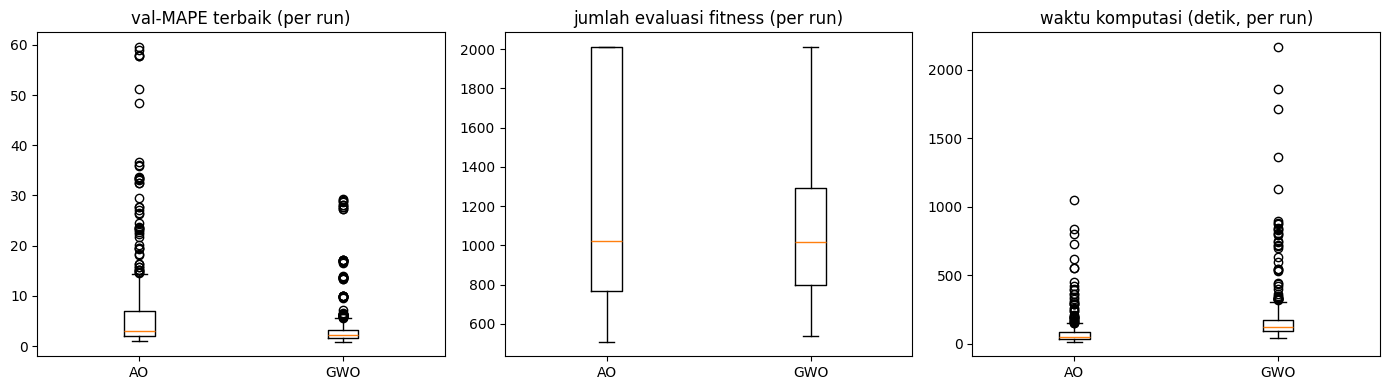

In [ ]:
fa = full_df.copy()
fa["n_eval"] = N_POPULATION * (fa["n_iter_actual"] + 1)
fa["detik_per_eval"] = fa["waktu_detik"] / fa["n_eval"]
fa["berhenti_awal"] = fa["n_iter_actual"] < T_ITERATIONS

ringkas_opt = fa.groupby("optimizer").agg(
    val_MAPE_terbaik_mean=("val_fitness_best", "mean"), val_MAPE_terbaik_median=("val_fitness_best", "median"),
    iter_aktual_mean=("n_iter_actual", "mean"), n_eval_mean=("n_eval", "mean"),
    waktu_detik_mean=("waktu_detik", "mean"), detik_per_eval_mean=("detik_per_eval", "mean"),
    pct_run_berhenti_awal=("berhenti_awal", lambda s: 100 * s.mean()))
display(ringkas_opt.round(4))

# Uji berpasangan per saham (rata-rata 10 run per saham)
per_saham = fa.groupby(["ticker", "optimizer"])[["val_fitness_best", "n_iter_actual", "n_eval", "waktu_detik"]].mean().unstack("optimizer").loc[UNIVERSE]
rows = []
for col, nama in [("val_fitness_best", "val-MAPE terbaik (fitness)"), ("n_iter_actual", "iterasi aktual"),
                  ("n_eval", "jumlah evaluasi fitness"), ("waktu_detik", "waktu komputasi (detik)")]:
    a, g = per_saham[(col, "AO")], per_saham[(col, "GWO")]
    W, p = wilcoxon(a, g)
    rows.append(dict(ukuran=nama, mean_AO=a.mean(), mean_GWO=g.mean(), median_selisih_AO_minus_GWO=(a - g).median(),
                     n_saham_AO_lebih_kecil=int((a < g).sum()), W=W, p_wilcoxon=p))
uji_opt = pd.DataFrame(rows)
display(uji_opt.round(4))
uji_opt.to_csv(OUT / "final" / "uji_proses_optimasi.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, ttl in zip(axes, ["val_fitness_best", "n_eval", "waktu_detik"],
                        ["val-MAPE terbaik (per run)", "jumlah evaluasi fitness (per run)", "waktu komputasi (detik, per run)"]):
    ax.boxplot([fa[fa.optimizer == "AO"][col], fa[fa.optimizer == "GWO"][col]])
    ax.set_xticklabels(["AO", "GWO"]); ax.set_title(ttl)
plt.tight_layout(); plt.savefig(OUT / "final" / "proses_optimasi_boxplot.png", dpi=130); plt.show()

### 6.2 Kurva konvergensi
Run 1 (seed 1) dijalankan ulang pada tiga saham (volatilitas train terendah, median, tertinggi) untuk menampilkan riwayat fitness per iterasi (riwayat tidak disimpan di checkpoint). Hasil akhir dibandingkan dengan checkpoint sebagai verifikasi reproducibility. Garis putus-putus = 2/3 T (titik pergantian eksplorasi → eksploitasi pada AO).

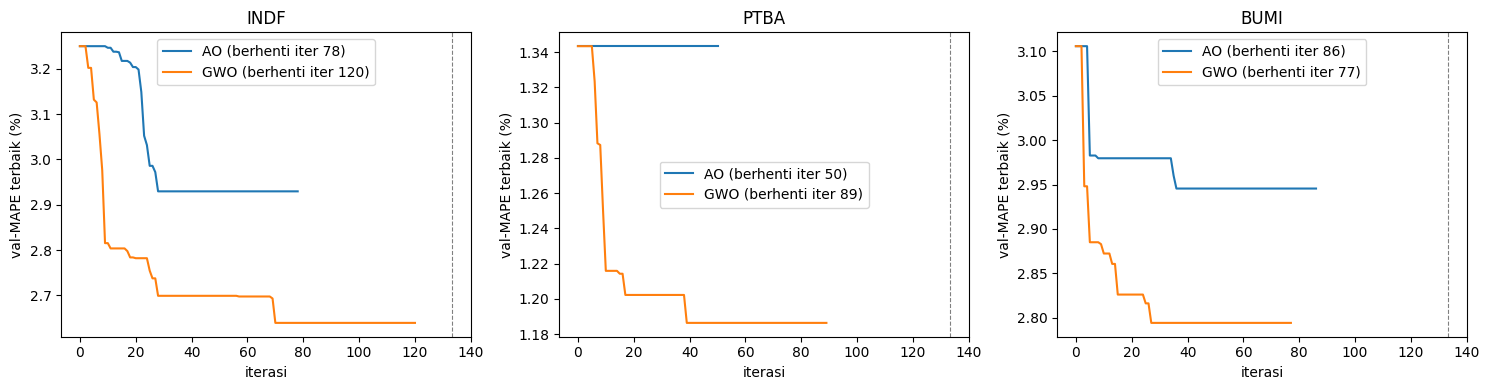

,ticker,optimizer,fitness_ulang,fitness_checkpoint,selisih
0,INDF,AO,2.93,2.93,0.00
1,INDF,GWO,2.64,2.64,0.00
2,PTBA,AO,1.34,1.34,0.00
3,PTBA,GWO,1.19,1.19,0.00
4,BUMI,AO,2.95,2.95,0.00
5,BUMI,GWO,2.79,2.79,0.00


Reproducible terhadap checkpoint: True


In [ ]:
CONV_STOCKS = [vol_train.index[0], vol_train.index[len(vol_train) // 2], vol_train.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
conv_check = []
for ax, t in zip(axes, CONV_STOCKS):
    obj = lambda pos, t=t: fitness(pos, data_split[t])
    for opt, fn, col in [("AO", AO_optimize, "tab:blue"), ("GWO", GWO_optimize, "tab:orange")]:
        bp, fb, hist, el, nit = fn(obj, Lb, Ub, DIM, N_POPULATION, T_ITERATIONS, SEEDS[0], patience=PATIENCE)
        ck = full_df[(full_df.ticker == t) & (full_df.optimizer == opt) & (full_df.run == 1)]["val_fitness_best"].iloc[0]
        conv_check.append(dict(ticker=t, optimizer=opt, fitness_ulang=fb, fitness_checkpoint=ck, selisih=abs(fb - ck)))
        ax.plot(hist, color=col, label=f"{opt} (berhenti iter {nit})")
    ax.axvline(2 * T_ITERATIONS / 3, color="gray", ls="--", lw=0.8)
    ax.set_title(t); ax.set_xlabel("iterasi"); ax.set_ylabel("val-MAPE terbaik (%)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "final" / "kurva_konvergensi.png", dpi=130); plt.show()

conv_check = pd.DataFrame(conv_check)
display(conv_check.round(8))
print("Reproducible terhadap checkpoint:", bool((conv_check.selisih < 1e-6).all()))

### 6.3 Hyperparameter hasil optimasi

In [ ]:
idx_best = full_df.groupby(["ticker", "optimizer"])["val_fitness_best"].idxmin()
best_runs = full_df.loc[idx_best].reset_index(drop=True)      # run terbaik (val-MAPE terendah) per saham x optimizer
print(f"Dipilih {len(best_runs)} kombinasi ({len(UNIVERSE)} saham x 2 optimizer) berdasarkan val_fitness_best terendah.")

hp_df = pd.DataFrame([dict(ticker=r["ticker"], optimizer=r["optimizer"], **r["best_params"]) for _, r in best_runs.iterrows()])
hp_df.to_csv(OUT / "final" / "hyperparameter_terpilih.csv", index=False)

rows = []
for col in PARAM_NAMES:
    a = hp_df[hp_df.optimizer == "AO"].set_index("ticker")[col].loc[UNIVERSE]
    g = hp_df[hp_df.optimizer == "GWO"].set_index("ticker")[col].loc[UNIVERSE]
    try:
        p = wilcoxon(a, g).pvalue
    except ValueError:
        p = np.nan
    rows.append(dict(hyperparameter=col, rentang=str(BOUNDS[PARAM_NAMES.index(col)]), mean_AO=a.mean(), mean_GWO=g.mean(),
                     median_AO=a.median(), median_GWO=g.median(), p_wilcoxon=p))
hp_summary = pd.DataFrame(rows)
rows_p = hp_summary["p_wilcoxon"].values
hp_summary["p_holm"] = np.nan
ok = ~np.isnan(rows_p)
hp_summary.loc[ok, "p_holm"] = multipletests(rows_p[ok], method="holm")[1]
display(hp_summary.round(4))
display(hp_df.sort_values(["ticker", "optimizer"]).round(4))

Dipilih 74 kombinasi (37 saham x 2 optimizer) berdasarkan val_fitness_best terendah.


,hyperparameter,rentang,mean_AO,mean_GWO,median_AO,median_GWO,p_wilcoxon,p_holm
0,n_estimators,"(50, 300)",131.38,147.24,94.00,127.00,0.43,1.00
1,learning_rate,"(0.01, 0.2)",0.09,0.15,0.09,0.16,0.00,0.00
2,max_depth,"(3, 10)",5.73,5.84,5.00,6.00,0.76,1.00
3,subsample,"(0.5, 1.0)",0.73,0.66,0.72,0.62,0.05,0.29
4,colsample_bytree,"(0.5, 1.0)",0.71,0.72,0.72,0.71,0.73,1.00
5,gamma,"(0, 5)",0.05,0.01,0.00,0.00,0.02,0.14
6,reg_alpha,"(0, 1)",0.17,0.17,0.08,0.01,0.29,1.00
7,reg_lambda,"(0, 1)",0.14,0.16,0.04,0.05,0.95,1.00


,ticker,optimizer,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda
0,ACES,AO,246,0.16,9,0.69,0.59,0.04,0.60,0.67
1,ACES,GWO,210,0.20,6,0.95,0.60,0.00,0.20,0.12
2,ADRO,AO,62,0.09,4,0.63,0.62,0.02,0.21,0.20
3,ADRO,GWO,167,0.20,7,0.62,0.64,0.01,0.89,1.00
4,AKRA,AO,215,0.17,5,0.93,0.92,0.17,0.69,0.02
5,AKRA,GWO,104,0.15,6,0.76,0.59,0.00,0.84,0.01
6,AMRT,AO,92,0.12,5,0.80,0.79,0.00,0.10,0.09
7,AMRT,GWO,170,0.20,3,0.87,0.99,0.00,0.00,0.01
8,ANTM,AO,88,0.05,6,0.54,0.55,0.00,0.20,0.00
9,ANTM,GWO,82,0.20,10,1.00,0.71,0.03,0.03,0.04


## 7. Evaluasi kinerja AO–XGBoost vs GWO–XGBoost: MAPE, RMSE, MAE, R² (Tujuan 3)

Setiap run dievaluasi ulang (refit XGBoost dengan hyperparameter run tersebut) pada train, validation, dan test. Model yang dilaporkan per saham = run dengan val-MAPE terendah (seleksi hanya dari validation, bukan test). Seluruh metrik pada skala Rupiah.

In [ ]:
run_rows = []
for i, row in full_df.iterrows():
    t = row["ticker"]; s = data_split[t]
    model = xgb.XGBRegressor(**FIXED_XGB_PARAMS, **row["best_params"]).fit(s["X_train"], s["y_train"])
    r = dict(ticker=t, optimizer=row["optimizer"], run=row["run"], seed=row["seed"], val_fitness_best=row["val_fitness_best"],
             waktu_detik=row["waktu_detik"], n_iter_actual=row["n_iter_actual"])
    for part in ["train", "val", "test"]:
        m = all_metrics(inv_y(s, s[f"y_{part}"]), inv_y(s, model.predict(s[f"X_{part}"])))
        for k, v in m.items():
            r[f"{part}_{k}"] = v
    run_rows.append(r)
    if (i + 1) % 100 == 0:
        print(f"  {i + 1}/{len(full_df)} run dievaluasi...")
run_eval_df = pd.DataFrame(run_rows)
run_eval_df.to_csv(OUT / "final" / "run_eval_all.csv", index=False)

# val-MAPE hasil refit harus sama dengan fitness yang dilaporkan optimizer
print("Selisih maks (val_MAPE refit - val_fitness_best):", float((run_eval_df.val_MAPE - run_eval_df.val_fitness_best).abs().max()), "(harus ~0)")

idx_b = run_eval_df.groupby(["ticker", "optimizer"])["val_fitness_best"].idxmin()
final_tbl = run_eval_df.loc[idx_b].reset_index(drop=True)
final_tbl["overfit_gap"] = final_tbl["test_MAPE"] - final_tbl["train_MAPE"]       # test - train
final_tbl["gap_val_test"] = final_tbl["test_MAPE"] - final_tbl["val_MAPE"]
final_tbl.to_csv(OUT / "final" / "final_tbl.csv", index=False)
print(f"final_tbl: {len(final_tbl)} baris")

  100/740 run dievaluasi...
  200/740 run dievaluasi...
  300/740 run dievaluasi...
  400/740 run dievaluasi...
  500/740 run dievaluasi...
  600/740 run dievaluasi...
  700/740 run dievaluasi...
Selisih maks (val_MAPE refit - val_fitness_best): 0.0 (harus ~0)
final_tbl: 74 baris


### 7.0 Tabel evaluasi lengkap (satu tabel): MAPE, RMSE, MAE, R² pada train, validation, dan test

In [ ]:
URUT = [f"{part}_{m}" for part in ["train", "val", "test"] for m in ["MAPE", "RMSE", "MAE", "R2"]]
tabel_eval = final_tbl.sort_values(["ticker", "optimizer"]).set_index(["ticker", "optimizer"])[URUT + ["overfit_gap"]]

# baris ringkasan: rata-rata dan median 37 saham per optimizer
ringkas_baris = pd.concat({f"RATA-RATA ({o})": final_tbl[final_tbl.optimizer == o][URUT + ["overfit_gap"]].mean() for o in ["AO", "GWO"]} |
                          {f"MEDIAN ({o})": final_tbl[final_tbl.optimizer == o][URUT + ["overfit_gap"]].median() for o in ["AO", "GWO"]}, axis=1).T
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
display(tabel_eval.round(3))
display(ringkas_baris.round(3))
tabel_eval.to_csv(OUT / "final" / "tabel_evaluasi_lengkap.csv")

train_MAPE  train_RMSE  train_MAE  train_R2  val_MAPE  val_RMSE  val_MAE  val_R2  test_MAPE  test_RMSE  test_MAE  test_R2  overfit_gap
ticker optimizer                                                                                                                                        
ACES   AO              2.639      32.222     21.981     0.992     2.093    21.675   15.945   0.928     10.173     53.118    44.935   -0.399        7.534
       GWO             1.839      22.291     16.536     0.996     1.892    20.261   14.457   0.937      4.177     23.839    18.586    0.718        2.338
ADRO   AO              2.217      67.936     50.198     0.993     2.350   119.492   65.513   0.970      2.333     60.000    43.583    0.789        0.116
       GWO             2.353      71.297     53.088     0.992     2.235   116.902   62.418   0.971      3.065     72.038    57.077    0.696        0.712
AKRA   AO              2.786      40.734     28.722     0.987     2.106    36.571   27.491   0.946      2.331     36.197    27.946    0.756       -0.455
       GWO             1.929      29.037     20.902     0.994     1.960    34.815   25.529   0.951      2.118     34.613    25.441    0.777        0.189
AMRT   AO              1.492      37.880     27.883     0.998     3.791   173.353  113.313   0.654      2.493     69.846    53.790    0.896        1.001
       GWO             0.758      17.565     13.687     0.999     3.087   136.509   90.678   0.785      2.475     69.581    52.765    0.897        1.717
ANTM   AO              1.903      57.314     39.791     0.975     2.167    42.772   31.904   0.841     10.396    390.786   326.439    0.222        8.493
       GWO             1.916      57.307     40.106     0.975     2.055    41.278   30.363   0.852      9.445    354.501   295.872    0.360        7.528
ASII   AO              1.284     100.757     75.081     0.978     1.300    84.233   63.585   0.866      1.494    109.307    81.610    0.978        0.211
       GWO             1.117      85.654     65.410     0.984     1.217    80.718   59.614   0.877      1.455    110.466    79.919    0.978        0.339
BBCA   AO              0.616      55.474     47.827     0.998     2.210   272.447  223.201   0.809      1.473    166.311   122.558    0.891        0.857
       GWO             0.029       3.042      2.316     1.000     1.642   204.191  163.249   0.893      1.666    183.816   138.244    0.866        1.637
BBNI   AO              1.201      66.222     47.508     0.995     1.930   116.713   92.710   0.940      1.737     95.638    73.578    0.721        0.536
       GWO             1.610      89.422     61.964     0.990     1.810   114.790   86.245   0.942      1.811    100.591    76.545    0.691        0.200
BBRI   AO              1.727     106.569     78.019     0.975     1.742    98.326   76.126   0.958      1.947     98.343    74.800    0.750        0.219
       GWO             1.330      80.744     60.490     0.986     1.684    94.617   73.779   0.961      1.627     84.388    62.922    0.816        0.296
BBTN   AO              0.070       1.247      0.949     1.000     7.214   117.102   69.671   0.660      4.817     80.996    50.189    0.439        4.748
       GWO             0.028       0.482      0.385     1.000     5.966    97.225   58.279   0.766      4.080     68.867    43.299    0.594        4.052
BMRI   AO              1.227      75.352     54.857     0.996     1.955   150.112  118.391   0.966      1.999    130.743    95.397    0.804        0.772
       GWO             1.135      69.398     50.822     0.997     1.817   143.185  109.832   0.969      2.050    134.047    97.582    0.794        0.916
BRPT   AO              2.215      32.192     21.592     0.959     2.558    34.171   23.848   0.926     34.080  1,395.273 1,065.294   -0.590       31.866
       GWO             2.133      30.162     20.649     0.964     2.409    32.763   22.625   0.932     33.557  1,384.843 1,053.285   -0.566       31.424
BUMI   AO              4.436       5.876

,train_MAPE,train_RMSE,train_MAE,train_R2,val_MAPE,val_RMSE,val_MAE,val_R2,test_MAPE,test_RMSE,test_MAE,test_R2,overfit_gap
RATA-RATA (AO),1.656,92.502,67.436,0.985,4.665,179.199,126.546,0.692,7.624,254.088,193.390,-1.034,5.968
RATA-RATA (GWO),1.455,80.906,59.653,0.988,3.942,158.859,108.225,0.772,6.698,233.832,175.499,-0.615,5.243
MEDIAN (AO),1.399,51.449,39.017,0.990,2.301,84.233,63.585,0.890,2.858,109.307,81.610,0.715,1.630
MEDIAN (GWO),1.433,49.120,38.139,0.990,2.055,80.718,58.279,0.900,2.745,110.466,79.919,0.728,1.637


### 7.1 Ringkasan metrik per optimizer (rata-rata 37 saham)

In [ ]:
agg = {}
for part in ["train", "val", "test"]:
    for m in ["MAPE", "RMSE", "MAE", "R2"]:
        agg[f"{part}_{m}"] = "mean"
ringkas_metrik = final_tbl.groupby("optimizer").agg(agg)
print("Rata-rata per optimizer:"); display(ringkas_metrik.round(4))

print("\nMedian test per optimizer:")
display(final_tbl.groupby("optimizer")[["test_MAPE", "test_RMSE", "test_MAE", "test_R2"]].median().round(4))
print("\nSD antar-saham test per optimizer:")
display(final_tbl.groupby("optimizer")[["test_MAPE", "test_RMSE", "test_MAE", "test_R2"]].std().round(4))

# Pembanding sebelum optimasi: XGBoost dengan hyperparameter default (FIXED_XGB_PARAMS saja)
xgb_default = {}
for t in UNIVERSE:
    s = data_split[t]
    m = xgb.XGBRegressor(**FIXED_XGB_PARAMS).fit(s["X_train"], s["y_train"])
    xgb_default[t] = all_metrics(inv_y(s, s["y_test"]), inv_y(s, m.predict(s["X_test"])))
xgb_default_df = pd.DataFrame(xgb_default).T.loc[UNIVERSE]
print("\nXGBoost default (tanpa optimasi), rata-rata test 37 saham:")
display(xgb_default_df.mean().round(4).to_frame("XGBoost default").T)

Rata-rata per optimizer:


,train_MAPE,train_RMSE,train_MAE,train_R2,val_MAPE,val_RMSE,val_MAE,val_R2,test_MAPE,test_RMSE,test_MAE,test_R2
optimizer,,,,,,,,,,,,
AO,1.656,92.502,67.436,0.986,4.665,179.199,126.546,0.692,7.624,254.088,193.390,-1.034
GWO,1.455,80.906,59.653,0.988,3.942,158.859,108.225,0.772,6.698,233.832,175.499,-0.615



Median test per optimizer:


,test_MAPE,test_RMSE,test_MAE,test_R2
optimizer,,,,
AO,2.858,109.307,81.610,0.715
GWO,2.745,110.466,79.919,0.728



SD antar-saham test per optimizer:


,test_MAPE,test_RMSE,test_MAE,test_R2
optimizer,,,,
AO,10.383,316.688,262.393,8.071
GWO,9.205,295.974,242.066,6.501



XGBoost default (tanpa optimasi), rata-rata test 37 saham:


,MAPE,RMSE,MAE,R2
XGBoost default,7.982,276.909,214.021,-1.347


In [ ]:
# Cek konsistensi dengan angka run final sebelumnya (rata-rata test MAPE 37 saham)
ACUAN = dict(AO=7.6238, GWO=6.6983, xgb_default=7.9823)
cek = dict(AO=final_tbl[final_tbl.optimizer == "AO"]["test_MAPE"].mean(),
           GWO=final_tbl[final_tbl.optimizer == "GWO"]["test_MAPE"].mean(),
           xgb_default=xgb_default_df["MAPE"].mean())
for k in ACUAN:
    print(f"{k:12s} sekarang={cek[k]:8.4f} | acuan={ACUAN[k]:.4f} ->", "COCOK" if abs(cek[k] - ACUAN[k]) < 0.01 else "BEDA (cek sumber data/konfigurasi)")

AO           sekarang=  7.6238 | acuan=7.6238 -> COCOK
GWO          sekarang=  6.6983 | acuan=6.6983 -> COCOK
xgb_default  sekarang=  7.9823 | acuan=7.9823 -> COCOK


### 7.2 Uji signifikansi AO vs GWO per metrik (Wilcoxon berpasangan antar-saham)

In [ ]:
def pivot_metric(col):
    return final_tbl.pivot(index="ticker", columns="optimizer", values=col).loc[UNIVERSE]

rows = []
for m, lebih_kecil_baik in [("MAPE", True), ("RMSE", True), ("MAE", True), ("R2", False)]:
    p_ = pivot_metric(f"test_{m}")
    a, g = p_["AO"], p_["GWO"]
    W, p = wilcoxon(a, g)
    n_ao_baik = int((a < g).sum()) if lebih_kecil_baik else int((a > g).sum())
    rows.append(dict(metrik=f"test_{m}", mean_AO=a.mean(), mean_GWO=g.mean(), median_AO=a.median(), median_GWO=g.median(),
                     median_selisih_AO_minus_GWO=(a - g).median(), saham_AO_lebih_baik=n_ao_baik,
                     saham_GWO_lebih_baik=len(a) - n_ao_baik, W=W, p_wilcoxon=p))
uji_metrik = pd.DataFrame(rows)
display(uji_metrik.round(4))
uji_metrik.to_csv(OUT / "final" / "uji_wilcoxon_per_metrik.csv", index=False)

# Bootstrap 95% CI median selisih MAPE (AO - GWO)
diff = (pivot_metric("test_MAPE")["AO"] - pivot_metric("test_MAPE")["GWO"]).values
rng = np.random.default_rng(42)
boot = [np.median(rng.choice(diff, size=len(diff), replace=True)) for _ in range(10000)]
ci = np.percentile(boot, [2.5, 97.5])
print(f"\nMedian selisih test MAPE (AO - GWO) = {np.median(diff):.4f} pp | 95% CI bootstrap = [{ci[0]:.4f}, {ci[1]:.4f}]")
print("(selisih < 0: AO lebih baik; > 0: GWO lebih baik)")

,metrik,mean_AO,mean_GWO,median_AO,median_GWO,median_selisih_AO_minus_GWO,saham_AO_lebih_baik,saham_GWO_lebih_baik,W,p_wilcoxon
0,test_MAPE,7.624,6.698,2.858,2.745,0.255,8,29,85.000,0.000
1,test_RMSE,254.088,233.832,109.307,110.466,7.806,9,28,100.000,0.000
2,test_MAE,193.390,175.499,81.610,79.919,6.275,8,29,83.000,0.000
3,test_R2,-1.034,-0.615,0.715,0.728,-0.025,9,28,92.000,0.000



Median selisih test MAPE (AO - GWO) = 0.2550 pp | 95% CI bootstrap = [0.1162, 0.6839]
(selisih < 0: AO lebih baik; > 0: GWO lebih baik)


### 7.3 Generalisasi (overfitting) dan stabilitas antar-run

In [ ]:
print("Overfit gap (test_MAPE - train_MAPE):")
display(final_tbl.groupby("optimizer")["overfit_gap"].agg(["mean", "median", "std"]).round(3))
of_ao, of_gwo = pivot_metric("overfit_gap")["AO"], pivot_metric("overfit_gap")["GWO"]
W, p = wilcoxon(of_ao, of_gwo)
print(f"Wilcoxon overfit_gap AO vs GWO: W={W:.2f}, p={p:.4f}")

print("\nRata-rata gap train -> val -> test per optimizer:")
display(final_tbl.groupby("optimizer")[["train_MAPE", "val_MAPE", "test_MAPE", "overfit_gap", "gap_val_test"]].mean().round(3))

# Stabilitas antar-run: SD antar 10 run per saham, dirata-ratakan antar saham
sd_rows = []
for t in UNIVERSE:
    for o in ["AO", "GWO"]:
        sub = run_eval_df[(run_eval_df.ticker == t) & (run_eval_df.optimizer == o)]
        r = dict(ticker=t, optimizer=o)
        for part in ["train", "test"]:
            for m in ["MAPE", "RMSE", "MAE"]:
                r[f"sd_{part}_{m}"] = sub[f"{part}_{m}"].std(ddof=1)
        sd_rows.append(r)
sd_tbl = pd.DataFrame(sd_rows)
print("\nRata-rata SD antar-run (10 run) per optimizer:")
display(sd_tbl.groupby("optimizer")[[c for c in sd_tbl.columns if c.startswith("sd_")]].mean().round(4))
sd_tbl.to_csv(OUT / "final" / "sd_antar_run.csv", index=False)

Overfit gap (test_MAPE - train_MAPE):


,mean,median,std
optimizer,,,
AO,5.968,1.630,10.524
GWO,5.243,1.637,9.355


Wilcoxon overfit_gap AO vs GWO: W=229.00, p=0.0653

Rata-rata gap train -> val -> test per optimizer:


,train_MAPE,val_MAPE,test_MAPE,overfit_gap,gap_val_test
optimizer,,,,,
AO,1.656,4.665,7.624,5.968,2.959
GWO,1.455,3.942,6.698,5.243,2.756



Rata-rata SD antar-run (10 run) per optimizer:


,sd_train_MAPE,sd_train_RMSE,sd_train_MAE,sd_test_MAPE,sd_test_RMSE,sd_test_MAE
optimizer,,,,,,
AO,0.722,36.669,24.722,1.752,43.675,41.462
GWO,0.174,8.320,5.878,0.233,6.499,5.805


## 8. Hasil prediksi per saham (Tujuan 2)

### 8.1 Tabel metrik per saham (train / val / test)

In [ ]:
kolom = ["ticker", "optimizer", "train_MAPE", "val_MAPE", "test_MAPE", "test_RMSE", "test_MAE", "test_R2",
         "train_R2", "val_R2", "overfit_gap", "gap_val_test", "waktu_detik", "n_iter_actual"]
tabel_saham = final_tbl[kolom].sort_values(["ticker", "optimizer"]).reset_index(drop=True)
display(tabel_saham.round(4))
tabel_saham.to_csv(OUT / "final" / "tabel_metrik_per_saham.csv", index=False)

# Perbandingan AO vs GWO berdampingan per saham
sb = pd.DataFrame({
    "MAPE_AO": pivot_metric("test_MAPE")["AO"], "MAPE_GWO": pivot_metric("test_MAPE")["GWO"],
    "RMSE_AO": pivot_metric("test_RMSE")["AO"], "RMSE_GWO": pivot_metric("test_RMSE")["GWO"],
    "MAE_AO": pivot_metric("test_MAE")["AO"], "MAE_GWO": pivot_metric("test_MAE")["GWO"],
    "R2_AO": pivot_metric("test_R2")["AO"], "R2_GWO": pivot_metric("test_R2")["GWO"]})
sb["selisih_MAPE_AO_minus_GWO"] = sb["MAPE_AO"] - sb["MAPE_GWO"]
sb["MAPE_terbaik"] = np.where(sb["MAPE_AO"] < sb["MAPE_GWO"], "AO", "GWO")
display(sb.sort_values("selisih_MAPE_AO_minus_GWO").round(4))
sb.to_csv(OUT / "final" / "perbandingan_per_saham.csv")
print("\nJumlah saham dengan test MAPE lebih kecil:", sb["MAPE_terbaik"].value_counts().to_dict())

best_mape = sb[["MAPE_AO", "MAPE_GWO"]].min(axis=1).sort_values()
print("\n10 saham dengan test MAPE terkecil (model terbaik per saham):")
display(sb.loc[best_mape.index[:10], ["MAPE_AO", "MAPE_GWO", "R2_AO", "R2_GWO"]].round(4))
print("\n10 saham dengan test MAPE terbesar (model terbaik per saham):")
display(sb.loc[best_mape.index[-10:], ["MAPE_AO", "MAPE_GWO", "R2_AO", "R2_GWO"]].round(4))

,ticker,optimizer,train_MAPE,val_MAPE,test_MAPE,test_RMSE,test_MAE,test_R2,train_R2,val_R2,overfit_gap,gap_val_test,waktu_detik,n_iter_actual
0,ACES,AO,2.639,2.093,10.173,53.118,44.935,-0.399,0.992,0.928,7.534,8.080,49.817,62
1,ACES,GWO,1.839,1.892,4.177,23.839,18.586,0.718,0.996,0.937,2.338,2.285,102.158,111
2,ADRO,AO,2.217,2.350,2.333,60.001,43.583,0.789,0.993,0.970,0.116,-0.017,83.258,200
3,ADRO,GWO,2.353,2.235,3.065,72.038,57.077,0.696,0.992,0.971,0.712,0.831,77.632,66
4,AKRA,AO,2.786,2.106,2.331,36.197,27.947,0.756,0.987,0.946,-0.455,0.225,36.016,52
5,AKRA,GWO,1.929,1.960,2.118,34.613,25.441,0.777,0.994,0.951,0.189,0.158,80.361,157
6,AMRT,AO,1.492,3.791,2.493,69.846,53.790,0.896,0.998,0.654,1.001,-1.298,168.831,200
7,AMRT,GWO,0.758,3.087,2.475,69.581,52.765,0.897,1.000,0.785,1.717,-0.612,235.022,103
8,ANTM,AO,1.903,2.167,10.396,390.786,326.439,0.222,0.975,0.841,8.493,8.229,118.498,200
9,ANTM,GWO,1.917,2.055,9.445,354.501,295.872,0.360,0.975,0.852,7.528,7.390,85.422,94


,MAPE_AO,MAPE_GWO,RMSE_AO,RMSE_GWO,MAE_AO,MAE_GWO,R2_AO,R2_GWO,selisih_MAPE_AO_minus_GWO,MAPE_terbaik
ticker,,,,,,,,,,
ADRO,2.333,3.065,60.001,72.038,43.583,57.077,0.789,0.696,-0.732,AO
EMTK,4.801,5.292,77.473,85.683,52.034,58.129,0.954,0.944,-0.491,AO
BBCA,1.473,1.666,166.311,183.816,122.558,138.244,0.891,0.866,-0.193,AO
BBNI,1.738,1.811,95.638,100.591,73.579,76.545,0.721,0.691,-0.073,AO
SCMA,3.162,3.232,13.801,13.859,8.951,9.260,0.979,0.979,-0.070,AO
BMRI,1.999,2.050,130.743,134.047,95.397,97.582,0.804,0.794,-0.051,AO
PTBA,1.156,1.166,51.956,52.262,28.960,29.219,0.938,0.937,-0.011,AO
JPFA,6.291,6.300,228.120,228.653,147.064,147.132,0.675,0.673,-0.009,AO
AMRT,2.493,2.475,69.846,69.581,53.790,52.765,0.896,0.897,0.019,GWO



Jumlah saham dengan test MAPE lebih kecil: {'GWO': 29, 'AO': 8}

10 saham dengan test MAPE terkecil (model terbaik per saham):


,MAPE_AO,MAPE_GWO,R2_AO,R2_GWO
ticker,,,,
ITMG,1.165,1.057,0.568,0.605
PTBA,1.156,1.166,0.938,0.937
ICBP,1.657,1.393,0.955,0.964
ASII,1.494,1.455,0.978,0.978
BBCA,1.473,1.666,0.891,0.866
UNTR,1.628,1.512,0.955,0.959
PGAS,1.727,1.587,0.814,0.839
BBRI,1.947,1.627,0.750,0.816
BBNI,1.738,1.811,0.721,0.691



10 saham dengan test MAPE terbesar (model terbaik per saham):


,MAPE_AO,MAPE_GWO,R2_AO,R2_GWO
ticker,,,,
JPFA,6.291,6.300,0.675,0.673
INKP,8.189,7.618,0.612,0.662
BUMI,8.931,8.207,0.403,0.473
MDKA,11.242,9.382,-0.028,0.257
ANTM,10.396,9.445,0.222,0.360
INCO,16.225,12.019,-0.059,0.328
TOWR,25.160,21.769,-9.649,-7.181
UNVR,38.332,31.688,-1.556,-0.751
BRPT,34.080,33.557,-0.590,-0.566


### 8.2 Prediksi vs aktual (train, validation, test) per saham
Prediksi dihitung ulang dari model terpilih (run dengan val-MAPE terendah). Satu gambar per saham (panel AO | GWO) disimpan di `workspace_audit/final/plots_prediksi/`.

Tersimpan 37 gambar di: workspace_audit\final\plots_prediksi


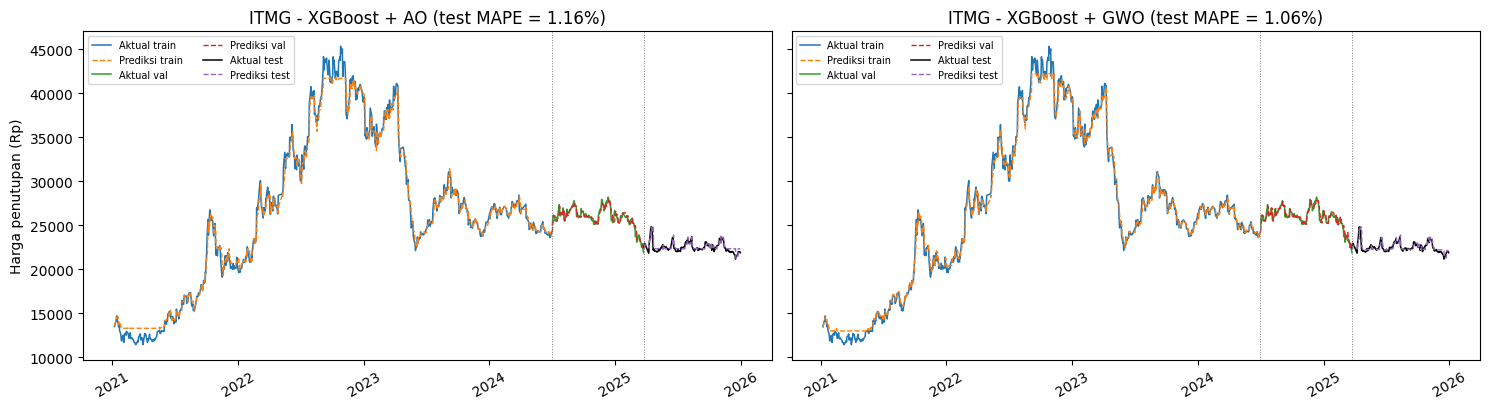

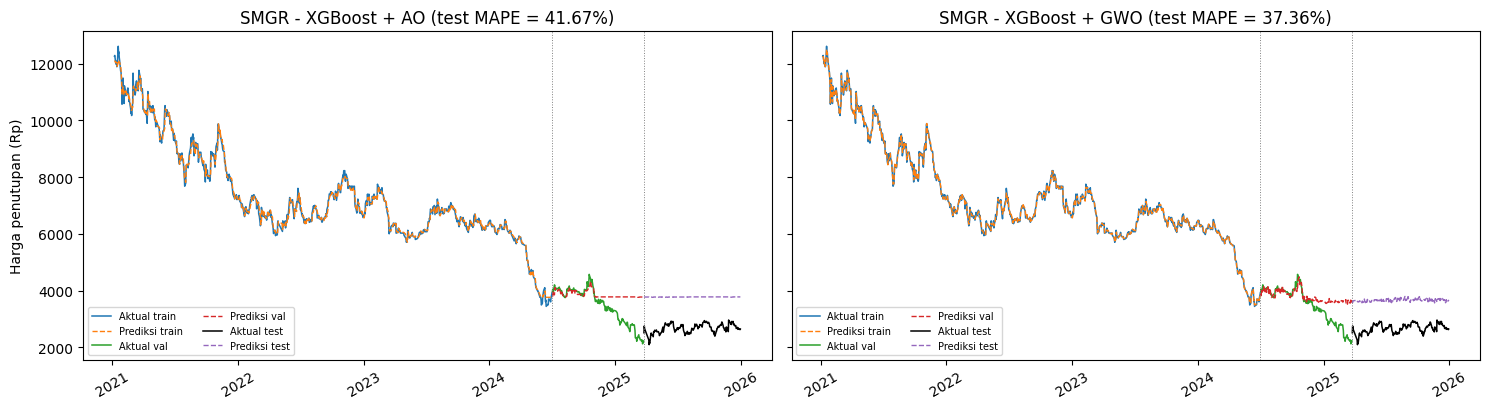

In [ ]:
preds = {}
for _, row in best_runs.iterrows():
    t, o = row["ticker"], row["optimizer"]
    s = data_split[t]
    model = xgb.XGBRegressor(**FIXED_XGB_PARAMS, **row["best_params"]).fit(s["X_train"], s["y_train"])
    preds[(t, o)] = {part: (inv_y(s, s[f"y_{part}"]), inv_y(s, model.predict(s[f"X_{part}"]))) for part in ["train", "val", "test"]}

plot_dir = OUT / "final" / "plots_prediksi"
WARNA = dict(train=("tab:blue", "tab:orange"), val=("tab:green", "tab:red"), test=("black", "tab:purple"))

def plot_saham(t, show=False):
    s = data_split[t]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
    for ax, o in zip(axes, ["AO", "GWO"]):
        for part in ["train", "val", "test"]:
            y_true, y_pred = preds[(t, o)][part]
            dates = s[f"{part}_dates"]
            ax.plot(dates, y_true, color=WARNA[part][0], lw=1.1, label=f"Aktual {part}")
            ax.plot(dates, y_pred, color=WARNA[part][1], lw=1, ls="--", label=f"Prediksi {part}")
        mt = final_tbl[(final_tbl.ticker == t) & (final_tbl.optimizer == o)]["test_MAPE"].iloc[0]
        ax.axvline(pd.Timestamp(CUT_TRAIN), color="gray", lw=0.7, ls=":"); ax.axvline(pd.Timestamp(CUT_VAL), color="gray", lw=0.7, ls=":")
        ax.set_title(f"{t} - XGBoost + {o} (test MAPE = {mt:.2f}%)"); ax.legend(fontsize=7, ncol=2)
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("Harga penutupan (Rp)")
    plt.tight_layout()
    plt.savefig(plot_dir / f"{t}_AO_vs_GWO.png", dpi=120)
    if show:
        plt.show()
    plt.close(fig)

for t in UNIVERSE:
    plot_saham(t)
print(f"Tersimpan {len(UNIVERSE)} gambar di: {plot_dir}")

# Contoh tampil di notebook: saham dengan test MAPE terkecil dan terbesar
for t in [best_mape.index[0], best_mape.index[-1]]:
    plot_saham(t, show=True)

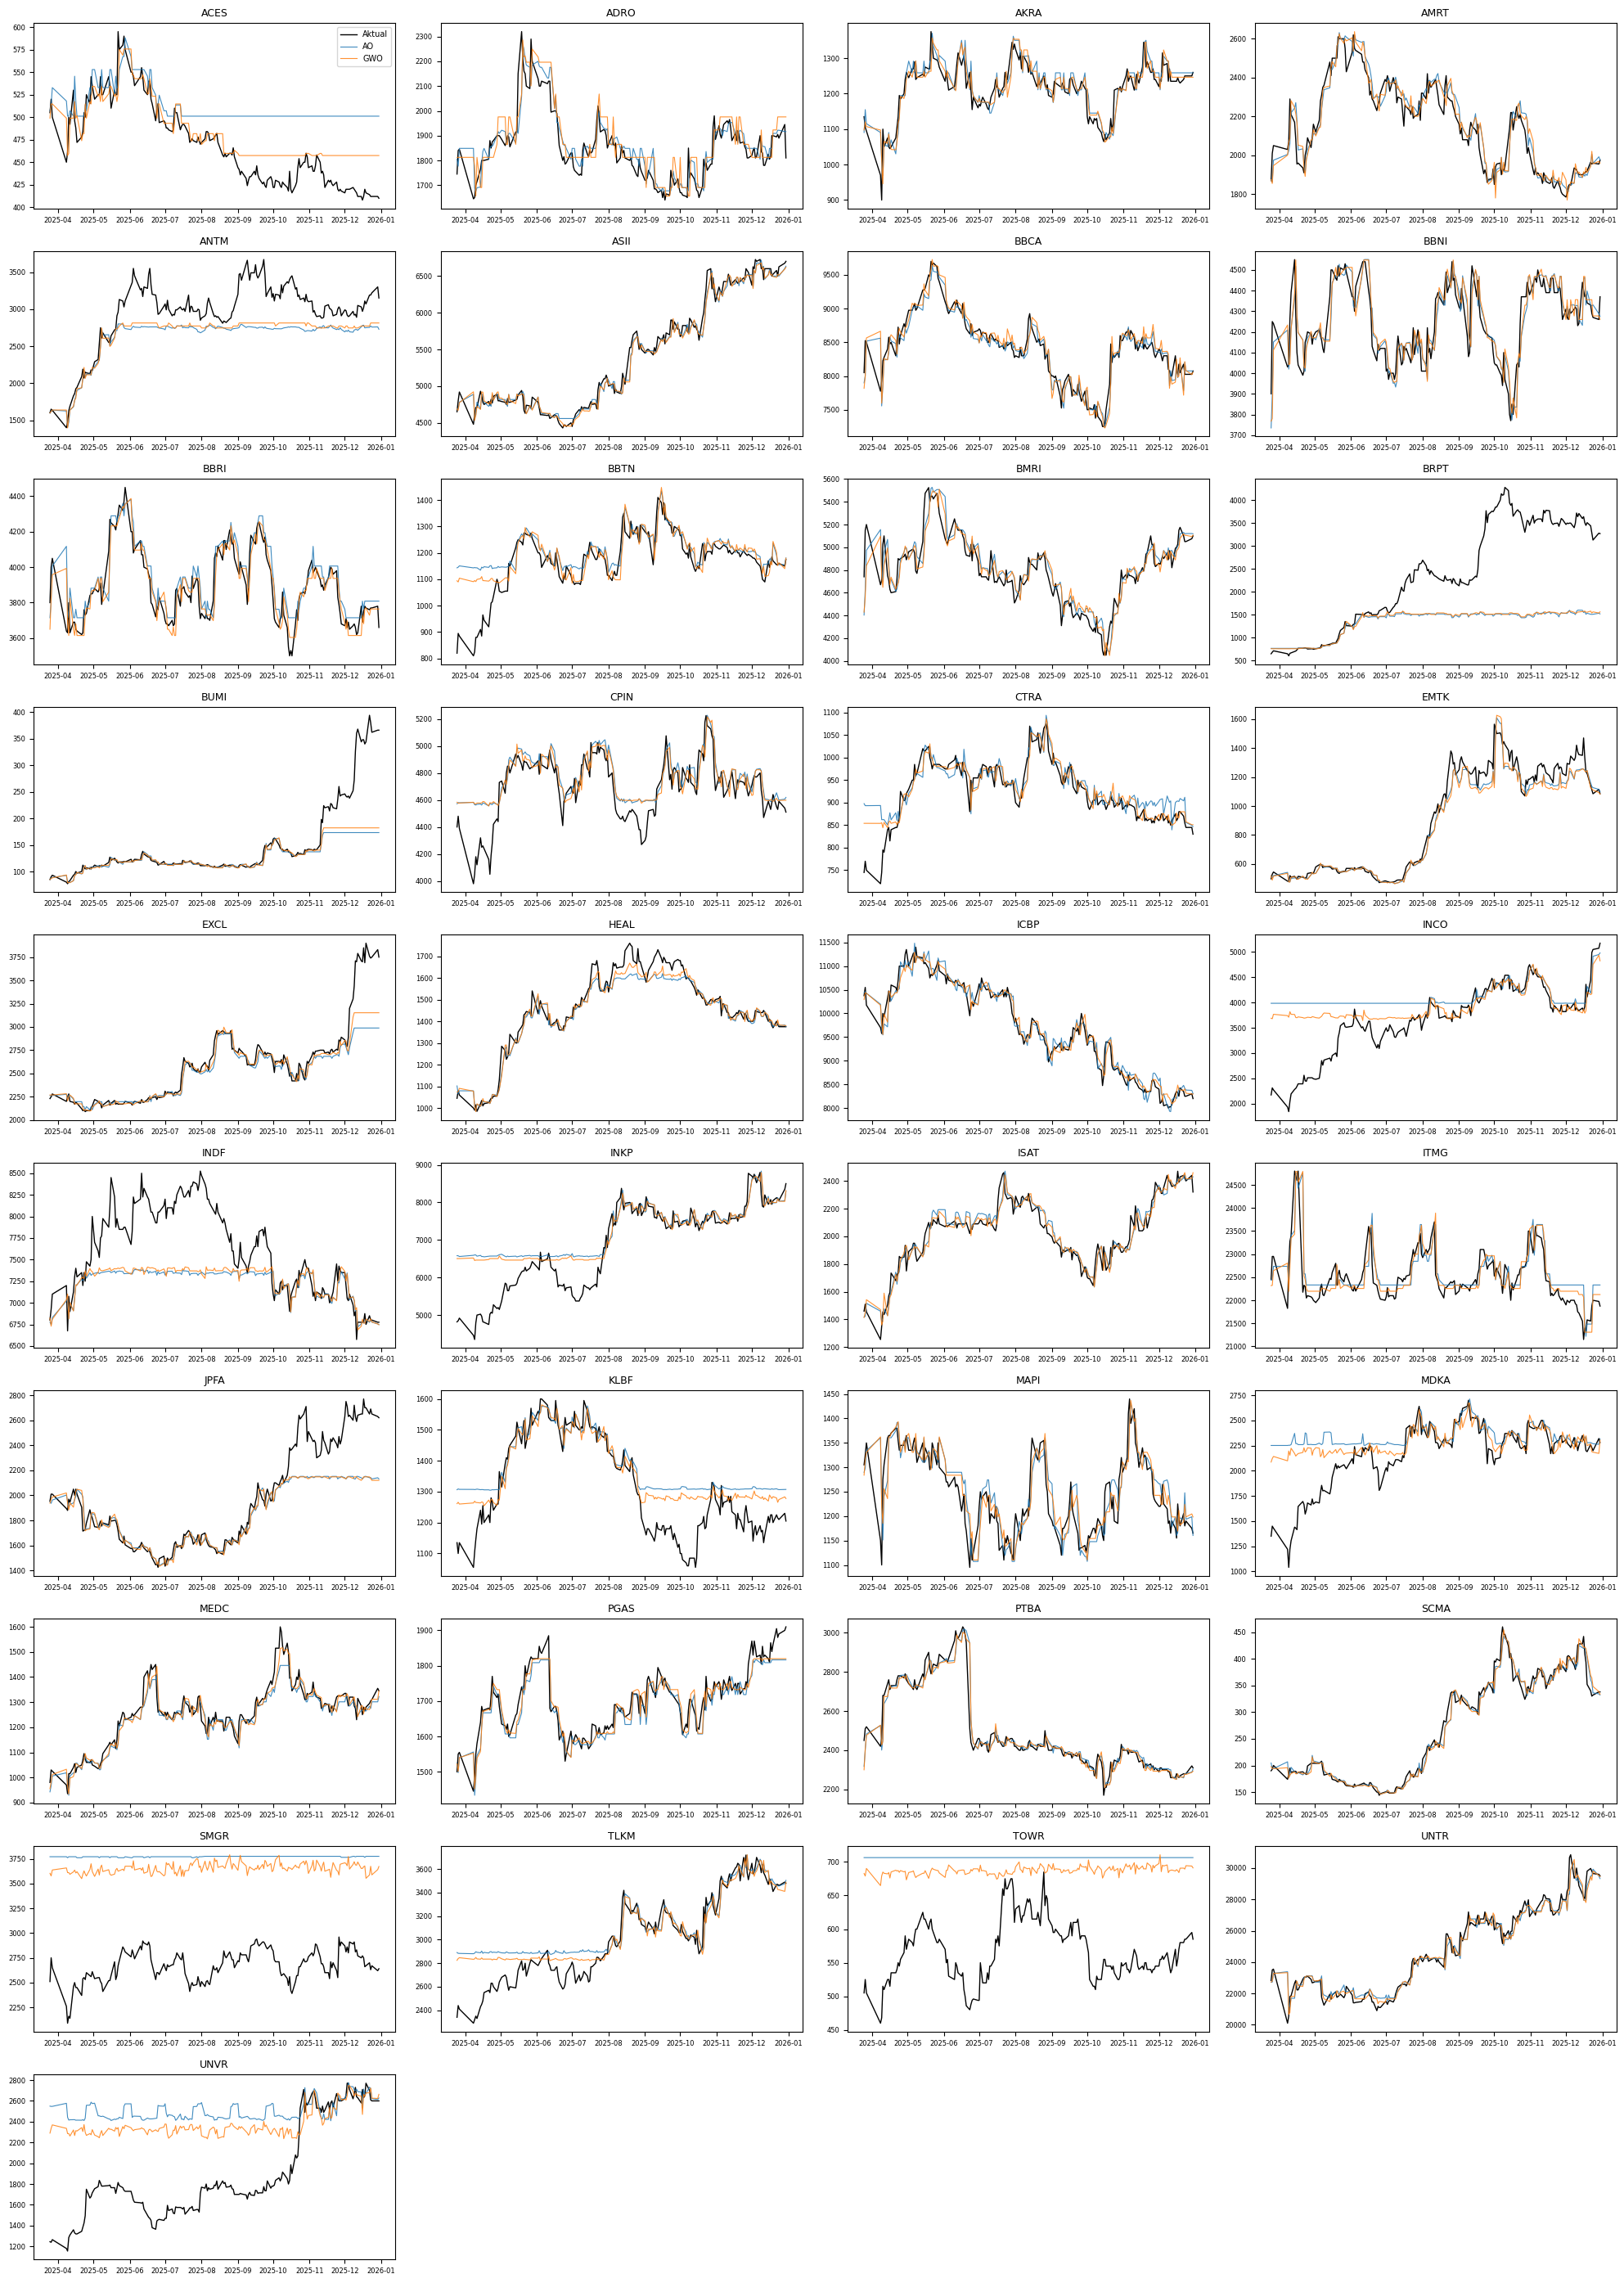

In [ ]:
# Panel semua saham, periode test saja
ncols = 4
nrows = int(np.ceil(len(UNIVERSE) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.8 * nrows))
axes = axes.flatten()
for ax, t in zip(axes, UNIVERSE):
    y_true, p_ao = preds[(t, "AO")]["test"]
    _, p_gwo = preds[(t, "GWO")]["test"]
    d = data_split[t]["test_dates"]
    ax.plot(d, y_true, color="black", lw=1, label="Aktual")
    ax.plot(d, p_ao, color="tab:blue", lw=0.8, alpha=0.85, label="AO")
    ax.plot(d, p_gwo, color="tab:orange", lw=0.8, alpha=0.85, label="GWO")
    ax.set_title(t, fontsize=9); ax.tick_params(labelsize=6)
for ax in axes[len(UNIVERSE):]:
    ax.axis("off")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "final" / "grid_prediksi_test.png", dpi=120); plt.show()

### 8.3 Perbandingan AO vs GWO per saham
(a) Uji Diebold–Mariano pada *percentage error* periode test, dengan varians HAC (Newey–West) + koreksi Harvey–Leybourne–Newbold dan koreksi Holm antar 37 saham (statistik < 0: AO lebih baik). (b) Perbandingan seluruh 10 run (Mann–Whitney antar-seed) dengan koreksi Holm.

In [ ]:
def dm_hac(d, h=1):
    """DM dengan varians HAC (Newey-West) + koreksi HLN. d = loss_A - loss_B; stat < 0 => A lebih baik."""
    d = np.asarray(d, float); n = len(d); d_bar = d.mean()
    max_lag = int(np.floor(4 * (n / 100) ** (2 / 9)))
    var_d = np.var(d, ddof=1)
    for lag in range(1, max_lag + 1):
        cov = np.cov(d[lag:], d[:-lag])[0, 1]
        var_d += 2 * (1 - lag / (max_lag + 1)) * cov
    var_d = max(var_d, 1e-12) / n
    stat = d_bar / np.sqrt(var_d)
    stat *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * (1 - stats.t.cdf(abs(stat), df=n - 1))

rows = []
for t in UNIVERSE:
    y_te, p_ao = preds[(t, "AO")]["test"]
    _, p_gwo = preds[(t, "GWO")]["test"]
    stat, p = dm_hac(np.abs(y_te - p_ao) / y_te * 100 - np.abs(y_te - p_gwo) / y_te * 100)
    rows.append(dict(ticker=t, DM_stat=stat, p_value=p))
dm_ao_gwo = pd.DataFrame(rows).set_index("ticker")
dm_ao_gwo["p_holm"] = multipletests(dm_ao_gwo["p_value"], method="holm")[1]
dm_ao_gwo["hasil_DM_holm"] = np.where(dm_ao_gwo.p_holm < 0.05, np.where(dm_ao_gwo.DM_stat < 0, "AO", "GWO"), "tidak beda")

# Perbandingan seluruh 10 run (seed-level)
rows = []
for t in UNIVERSE:
    a = run_eval_df[(run_eval_df.ticker == t) & (run_eval_df.optimizer == "AO")]["test_MAPE"]
    g = run_eval_df[(run_eval_df.ticker == t) & (run_eval_df.optimizer == "GWO")]["test_MAPE"]
    u, p = stats.mannwhitneyu(a, g, alternative="two-sided")
    rows.append(dict(ticker=t, median_AO=a.median(), median_GWO=g.median(), sd_AO=a.std(), sd_GWO=g.std(), p_seed=p))
seed_cmp = pd.DataFrame(rows).set_index("ticker")
seed_cmp["p_seed_holm"] = multipletests(seed_cmp["p_seed"], method="holm")[1]
seed_cmp["selisih_median"] = seed_cmp["median_AO"] - seed_cmp["median_GWO"]
seed_cmp["log_rasio"] = np.log(seed_cmp["median_AO"] / seed_cmp["median_GWO"])      # > 0: AO lebih buruk
seed_cmp["hasil_seed_holm"] = np.where(seed_cmp.p_seed_holm < 0.05, np.where(seed_cmp.selisih_median < 0, "AO", "GWO"), "tidak beda")

uji_saham = dm_ao_gwo.join(seed_cmp)
display(uji_saham.round(4))
uji_saham.to_csv(OUT / "final" / "uji_AO_vs_GWO_per_saham.csv")
print("\nDM (HAC + Holm), 37 saham      :", dm_ao_gwo["hasil_DM_holm"].value_counts().to_dict())
print("Seed-level (MWU + Holm), 37 saham:", seed_cmp["hasil_seed_holm"].value_counts().to_dict())

,DM_stat,p_value,p_holm,hasil_DM_holm,median_AO,median_GWO,sd_AO,sd_GWO,p_seed,p_seed_holm,selisih_median,log_rasio,hasil_seed_holm
ticker,,,,,,,,,,,,,
ACES,8.546,0.000,0.000,GWO,24.925,4.386,6.544,0.946,0.000,0.007,20.539,1.738,GWO
ADRO,-4.247,0.000,0.001,AO,2.531,2.235,0.248,0.395,0.345,1.000,0.296,0.124,tidak beda
AKRA,2.722,0.007,0.121,tidak beda,2.314,2.137,0.159,0.074,0.009,0.091,0.177,0.080,tidak beda
AMRT,0.176,0.860,1.000,tidak beda,2.597,2.417,0.141,0.149,0.104,0.520,0.180,0.072,tidak beda
ANTM,6.218,0.000,0.000,GWO,10.541,9.539,1.157,0.895,0.076,0.454,1.002,0.100,tidak beda
ASII,0.707,0.481,1.000,tidak beda,1.737,1.437,0.400,0.037,0.000,0.007,0.300,0.190,GWO
BBCA,-3.220,0.002,0.029,AO,1.363,1.626,0.044,0.113,0.000,0.007,-0.263,-0.176,AO
BBNI,-1.853,0.066,0.655,tidak beda,1.800,1.753,0.074,0.064,0.017,0.138,0.047,0.027,tidak beda
BBRI,3.474,0.001,0.015,GWO,2.164,1.718,0.473,0.054,0.001,0.012,0.446,0.231,GWO



DM (HAC + Holm), 37 saham      : {'GWO': 17, 'tidak beda': 17, 'AO': 3}
Seed-level (MWU + Holm), 37 saham: {'GWO': 26, 'tidak beda': 10, 'AO': 1}


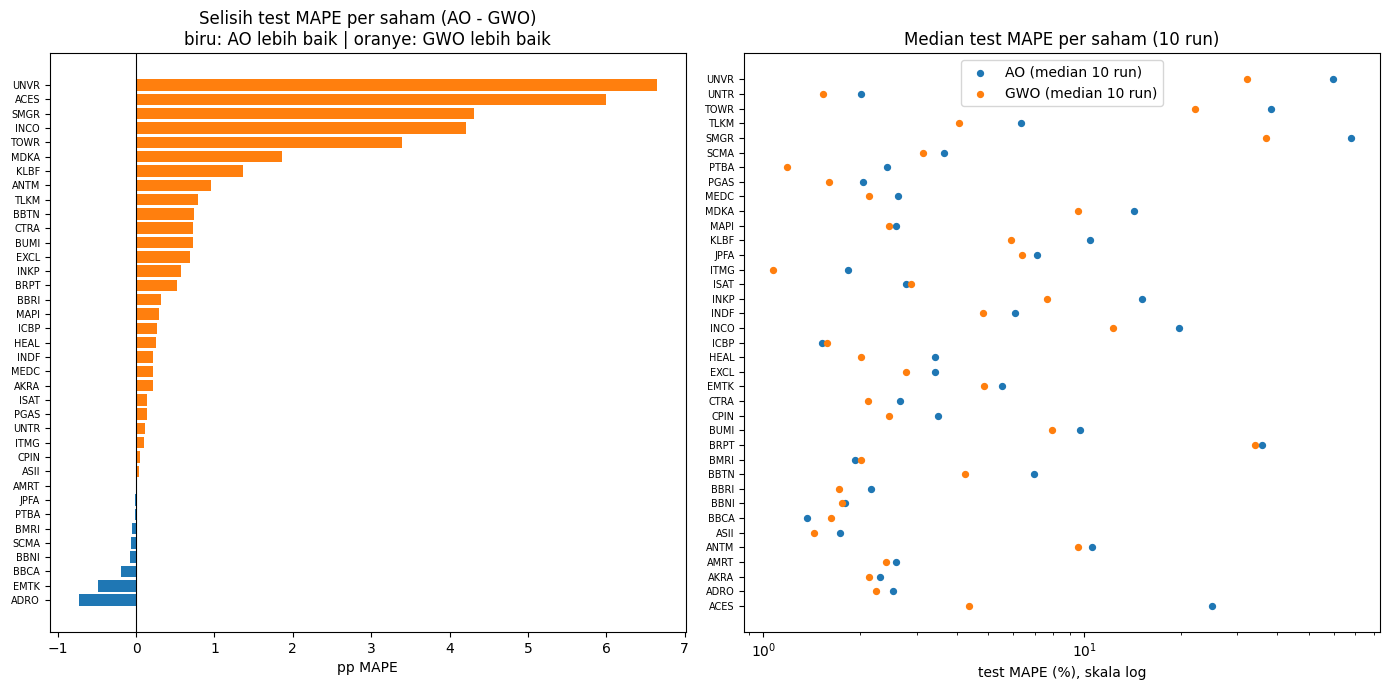

In [ ]:
# Visual: selisih test MAPE (AO - GWO) per saham, dan sebaran test MAPE antar-run pada beberapa saham
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
srt = sb.sort_values("selisih_MAPE_AO_minus_GWO")
axes[0].barh(srt.index, srt["selisih_MAPE_AO_minus_GWO"], color=np.where(srt["selisih_MAPE_AO_minus_GWO"] > 0, "tab:orange", "tab:blue"))
axes[0].axvline(0, color="black", lw=0.8); axes[0].tick_params(axis="y", labelsize=7)
axes[0].set_title("Selisih test MAPE per saham (AO - GWO)\nbiru: AO lebih baik | oranye: GWO lebih baik")
axes[0].set_xlabel("pp MAPE")

x = np.arange(len(UNIVERSE))
axes[1].scatter(seed_cmp["median_AO"], x, color="tab:blue", s=18, label="AO (median 10 run)")
axes[1].scatter(seed_cmp["median_GWO"], x, color="tab:orange", s=18, label="GWO (median 10 run)")
axes[1].set_yticks(x); axes[1].set_yticklabels(UNIVERSE, fontsize=7); axes[1].set_xscale("log")
axes[1].set_xlabel("test MAPE (%), skala log"); axes[1].legend(); axes[1].set_title("Median test MAPE per saham (10 run)")
plt.tight_layout(); plt.savefig(OUT / "final" / "perbandingan_AO_GWO_per_saham.png", dpi=130); plt.show()

## 9. Karakteristik saham vs selisih kinerja AO–GWO

Pertanyaan: apakah ada karakteristik saham yang berkaitan dengan selisih kinerja AO dan GWO? Seluruh karakteristik dihitung dari data yang tersedia sebelum test (volatilitas dari train saja) kecuali statistik deskriptif harga (periode penuh). Uji: Spearman dengan koreksi Holm atas seluruh pasangan (karakteristik × ukuran selisih).

,volatilitas_train,skewness_harga,level_harga_mean,std_harga,pct_test_diluar_rentang_train,n_lag_acf_signifikan,pct_hari_volume_nol
ACES,0.026,0.744,862.520,358.956,0.000,1,0.000
ADRO,0.026,0.169,"2,449.921",792.222,0.000,0,0.000
AKRA,0.024,-0.384,"1,195.301",316.974,0.000,2,0.080
AMRT,0.026,-0.490,"2,196.191",731.312,0.000,1,0.000
ANTM,0.028,0.579,"2,119.145",542.208,25.414,1,0.000
ASII,0.018,0.224,"5,681.120",738.883,0.000,1,0.000
BBCA,0.014,-0.212,"8,422.967","1,171.378",0.000,1,0.000
BBNI,0.018,-0.422,"4,271.176",838.815,0.000,1,0.000
BBRI,0.017,0.555,"4,507.410",655.617,0.000,3,0.000
BBTN,0.020,0.038,"1,322.340",169.292,16.022,0,0.000


,karakteristik,ukuran,rho,p,p_holm,signifikan_holm
0,pct_test_diluar_rentang_train,selisih_median,0.751,0.000,0.000,True
1,pct_test_diluar_rentang_train,log_rasio,0.406,0.013,0.166,False
2,skewness_harga,selisih_median,0.354,0.032,0.381,False
3,skewness_harga,log_rasio,0.205,0.223,1.000,False
4,volatilitas_train,selisih_median,0.171,0.313,1.000,False
5,pct_hari_volume_nol,log_rasio,0.132,0.435,1.000,False
6,level_harga_mean,selisih_median,-0.124,0.463,1.000,False
7,n_lag_acf_signifikan,log_rasio,-0.077,0.649,1.000,False
8,n_lag_acf_signifikan,selisih_median,-0.046,0.786,1.000,False
9,std_harga,selisih_median,-0.033,0.847,1.000,False


Jumlah pasangan signifikan setelah Holm: 1 dari 14


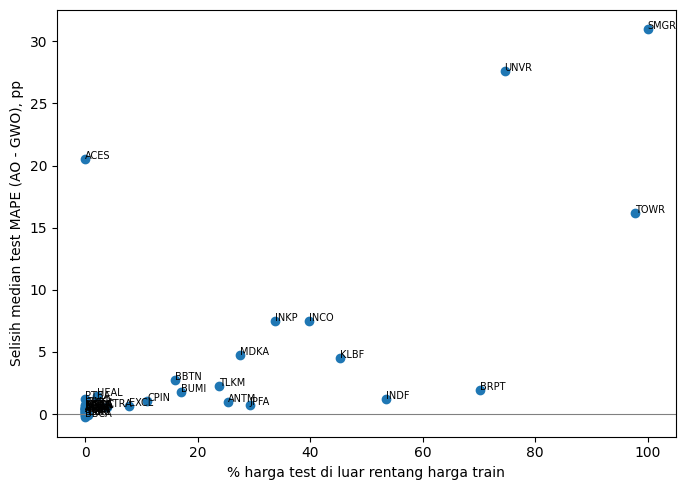

In [ ]:
# % harga test di luar rentang harga train (indikator ekstrapolasi; pohon keputusan tidak mengekstrapolasi)
extrap = {}
for t in UNIVERSE:
    s = data_split[t]
    y_tr, y_te = inv_y(s, s["y_train"]), inv_y(s, s["y_test"])
    extrap[t] = 100 * np.mean((y_te < y_tr.min()) | (y_te > y_tr.max()))
extrap_df = pd.Series(extrap, name="pct_test_diluar_rentang_train").to_frame()

chars = pd.DataFrame({
    "volatilitas_train": vol_train, "skewness_harga": desc["skew"], "level_harga_mean": desc["mean"], "std_harga": desc["std"],
    "pct_test_diluar_rentang_train": extrap_df["pct_test_diluar_rentang_train"],
    "n_lag_acf_signifikan": df_acf_summary["n_lag_signifikan"], "pct_hari_volume_nol": liq_tbl["pct_hari_volume_nol"],
}).reindex(UNIVERSE)
display(chars.round(3))

rows = []
for col in chars.columns:
    for ukuran in ["selisih_median", "log_rasio"]:
        sub = pd.concat([seed_cmp[ukuran], chars[col]], axis=1).dropna()
        rho, p = stats.spearmanr(sub.iloc[:, 0], sub.iloc[:, 1])
        rows.append(dict(karakteristik=col, ukuran=ukuran, rho=rho, p=p))
corr_tbl = pd.DataFrame(rows)
corr_tbl["p_holm"] = multipletests(corr_tbl["p"], method="holm")[1]
corr_tbl["signifikan_holm"] = corr_tbl["p_holm"] < 0.05
corr_tbl = corr_tbl.sort_values("p").reset_index(drop=True)
display(corr_tbl.round(4))
corr_tbl.to_csv(OUT / "final" / "korelasi_karakteristik_vs_selisih.csv", index=False)
print("Jumlah pasangan signifikan setelah Holm:", int(corr_tbl["signifikan_holm"].sum()), "dari", len(corr_tbl))

# Scatter: ekstrapolasi vs selisih MAPE
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(chars["pct_test_diluar_rentang_train"], seed_cmp["selisih_median"])
for t in UNIVERSE:
    ax.annotate(t, (chars.loc[t, "pct_test_diluar_rentang_train"], seed_cmp.loc[t, "selisih_median"]), fontsize=7)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("% harga test di luar rentang harga train"); ax.set_ylabel("Selisih median test MAPE (AO - GWO), pp")
plt.tight_layout(); plt.savefig(OUT / "final" / "ekstrapolasi_vs_selisih_AO_GWO.png", dpi=130); plt.show()

## 10. Ringkasan hasil

In [ ]:
ao = final_tbl[final_tbl.optimizer == "AO"].set_index("ticker").loc[UNIVERSE]
gw = final_tbl[final_tbl.optimizer == "GWO"].set_index("ticker").loc[UNIVERSE]
uji = uji_metrik.set_index("metrik")

print("=== Tujuan 1: proses optimasi ===")
print(f"Rata-rata iterasi aktual   : AO={fa[fa.optimizer=='AO'].n_iter_actual.mean():.1f} | GWO={fa[fa.optimizer=='GWO'].n_iter_actual.mean():.1f}")
print(f"Rata-rata evaluasi fitness : AO={fa[fa.optimizer=='AO'].n_eval.mean():.0f} | GWO={fa[fa.optimizer=='GWO'].n_eval.mean():.0f}")
print(f"Rata-rata val-MAPE terbaik : AO={fa[fa.optimizer=='AO'].val_fitness_best.mean():.4f} | GWO={fa[fa.optimizer=='GWO'].val_fitness_best.mean():.4f}")

print("\n=== Tujuan 3: kinerja pada test (rata-rata 37 saham) ===")
for m in ["MAPE", "RMSE", "MAE", "R2"]:
    u = uji.loc[f"test_{m}"]
    print(f"{m:5s}: AO={u.mean_AO:12.4f} | GWO={u.mean_GWO:12.4f} | Wilcoxon p={u.p_wilcoxon:.4f}")

print("\n=== Tujuan 2: per saham ===")
print("Saham dengan test MAPE lebih kecil:", sb["MAPE_terbaik"].value_counts().to_dict())
print("DM (HAC+Holm):", dm_ao_gwo["hasil_DM_holm"].value_counts().to_dict())
print("Seed-level (MWU+Holm):", seed_cmp["hasil_seed_holm"].value_counts().to_dict())

=== Tujuan 1: proses optimasi ===
Rata-rata iterasi aktual   : AO=118.5 | GWO=110.0
Rata-rata evaluasi fitness : AO=1195 | GWO=1110
Rata-rata val-MAPE terbaik : AO=6.9755 | GWO=4.0593

=== Tujuan 3: kinerja pada test (rata-rata 37 saham) ===
MAPE : AO=      7.6238 | GWO=      6.6983 | Wilcoxon p=0.0000
RMSE : AO=    254.0878 | GWO=    233.8318 | Wilcoxon p=0.0001
MAE  : AO=    193.3896 | GWO=    175.4993 | Wilcoxon p=0.0000
R2   : AO=     -1.0335 | GWO=     -0.6147 | Wilcoxon p=0.0000

=== Tujuan 2: per saham ===
Saham dengan test MAPE lebih kecil: {'GWO': 29, 'AO': 8}
DM (HAC+Holm): {'GWO': 17, 'tidak beda': 17, 'AO': 3}
Seed-level (MWU+Holm): {'GWO': 26, 'tidak beda': 10, 'AO': 1}
